# Lab Exercise 1 — Information Extraction from Aviation Safety Incident Reports
**Advance NLP (AML23702) · Department of AIML**

**Aim.** Build an information-extraction system that performs **POS tagging, named-entity recognition, relation extraction, event extraction and temporal ordering of events** on a text corpus, and present the results as annotated text, entity/relation tables, an event timeline / temporal graph and a knowledge graph.

**Corpus.** Aviation safety incident reports (semi-structured: a header of `KEY: value` fields followed by a free-text narrative and follow-up section). Two of the reports are *scanned images*, so an OCR stage is added in front of the NLP pipeline.

| Expected outcome (lab sheet) | Where in this notebook |
|---|---|
| Identify parts of speech | §2 POS tagging & dependency parse |
| Detect named entities (people, organisations, places, dates, domain terms) | §3 Hybrid NER (+ §4 optional Wikidata linking) |
| Extract relationships between entities | §5 Relation extraction |
| Detect events and time expressions | §6 Event extraction |
| Arrange events in temporal sequence | §7 Temporal ordering & DAG |
| Deliverables: annotated text, entity & relation tables, timeline / temporal graph | §9 Results, `outputs/` folder |
| Evaluation & analysis | §10 Evaluation against a hand-annotated gold standard |

**How to run.** `Kernel → Restart & Run All`. The notebook writes its own data (`sample_data/`, `gold/`) and all outputs (`outputs/`) into the folder it is opened from. Requirements: Python 3.10+, spaCy 3.7/3.8 with `en_core_web_sm`, OpenCV, PyTesseract **and the Tesseract binary** (`sudo apt install tesseract-ocr` on Linux/Colab, the UB-Mannheim installer on Windows), pandas, NetworkX, matplotlib, python-dateutil, Pillow.

In [10]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\Niyathi\Anaconda\python.exe
3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [15]:
%pip install pytesseract pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pytesseract
import os

tesseract_path = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

print("File exists:", os.path.exists(tesseract_path))

pytesseract.pytesseract.tesseract_cmd = tesseract_path

print("Tesseract version:", pytesseract.get_tesseract_version())

File exists: True
Tesseract version: 5.4.0.20240606


In [6]:
import pytesseract
from PIL import Image

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

print("Tesseract version:", pytesseract.get_tesseract_version())

Tesseract version: 5.4.0.20240606


In [8]:

# 0. Setup: install anything missing (safe to re-run)
import importlib.util
import os
import subprocess
import sys
import shutil

PACKAGES = {
    "spacy": "spacy>=3.7,<3.9",
    "cv2": "opencv-python-headless",
    "pytesseract": "pytesseract",
    "dateutil": "python-dateutil",
    "networkx": "networkx",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "PIL": "Pillow"
}

missing = [
    package
    for module, package in PACKAGES.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *missing
    ])

if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.check_call([
        sys.executable, "-m", "spacy",
        "download", "en_core_web_sm"
    ])

# Configure Tesseract for Windows
import pytesseract

TESSERACT_PATH = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

if os.path.isfile(TESSERACT_PATH):
    pytesseract.pytesseract.tesseract_cmd = TESSERACT_PATH
    print("Tesseract version:", pytesseract.get_tesseract_version())
else:
    print("Tesseract executable not found at:", TESSERACT_PATH)
    print("Please check its installation path.")

print("Setup complete.")


Tesseract version: 5.4.0.20240606
Setup complete.


In [9]:
import difflib, json, re, textwrap
from collections import Counter
from dataclasses import dataclass, field
from datetime import datetime
from functools import lru_cache
from itertools import combinations
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pytesseract
import spacy
from dateutil import parser as dateparser
from PIL import Image, ImageDraw, ImageFont
from spacy.language import Language
from spacy.tokens import Doc, Span
from spacy.util import filter_spans
from IPython.display import HTML, display

ROOT = Path.cwd()
pd.set_option("display.max_colwidth", 80)
print("spaCy", spacy.__version__, "| model", spacy.load("en_core_web_sm").meta["version"],
      "| OpenCV", cv2.__version__, "| Tesseract", pytesseract.get_tesseract_version())

spaCy 3.8.11 | model 3.8.0 | OpenCV 5.0.0 | Tesseract 5.4.0.20240606


## 1. Dataset / corpus

No licensed public corpus of Indian aviation incident reports is freely available, so the corpus is **five hand-authored reports** written in the register of real occurrence reports (operator, flight number, aircraft type and registration, ICAO airport codes, reporter, UTC times, a narrative and follow-up actions). All organisations and people are fictional; cities and regulators are real so entity linking can be demonstrated.

| File | Input type | Occurrence | Split |
|---|---|---|---|
| `incident_1.txt` | plain text | hydraulic warning → diversion | development |
| `incident_scan_1.png` | scanned image | severe turbulence, cabin-crew injuries | development |
| `incident_2.txt` | plain text | bird strike → return to departure airport | held-out test |
| `incident_scan_2.jpg` | scanned image | tow-bar failure during pushback | held-out test |
| `incident_3.txt` | plain text | cabin smoke → MAYDAY, evacuation | held-out test (written after the rules were frozen) |

The two "scans" are rendered from their transcriptions and then degraded the way real scans are (1.8° / −2.4° skew, uneven lighting, faded toner, sensor noise, JPEG compression). The clean transcriptions are kept as OCR ground truth. The gold annotations (entities, relations, events with dates) were written from the source text **before** the pipeline was run on it.

In [10]:
SAMPLE_TEXTS = {'incident_1.txt': 'AVIATION SAFETY INCIDENT REPORT\n'
                   'REPORT ID: ASR-2025-0417\n'
                   'OPERATOR: Skyline Regional Airways\n'
                   'FLIGHT: SR-482    AIRCRAFT: Airbus A320neo    REGISTRATION: VT-SKR\n'
                   'ROUTE: Bengaluru (VOBL) to Delhi (VIDP)\n'
                   'REPORTED BY: Captain Meera Nair\n'
                   'DATE OF OCCURRENCE: 14 March 2025\n'
                   'SEVERITY: Serious Incident\n'
                   '\n'
                   'NARRATIVE:\n'
                   'Flight SR-482 departed Bengaluru on 14 March 2025 at 06:10 UTC with\n'
                   '162 passengers and 6 crew on board. At 06:52 UTC the crew observed a\n'
                   'hydraulic pressure warning on the green system. Captain Meera Nair\n'
                   'declared a PAN-PAN and requested a diversion to Hyderabad (VOHS).\n'
                   'The aircraft diverted to Hyderabad and landed safely at 07:31 UTC.\n'
                   'Airport fire services inspected the landing gear on arrival.\n'
                   'No injuries were reported.\n'
                   '\n'
                   'FOLLOW-UP ACTIONS:\n'
                   'Skyline Regional Airways notified the Directorate General of Civil\n'
                   'Aviation on 14 March 2025. Engineers from AeroTech MRO Services\n'
                   'inspected the aircraft on 15 March 2025 and replaced a leaking\n'
                   'hydraulic pump. The aircraft was released to service on\n'
                   '17 March 2025. The Aircraft Accident Investigation Bureau opened an\n'
                   'investigation on 18 March 2025. Skyline Regional Airways will submit\n'
                   'the final report within 30 days. The flight crew completed recurrent\n'
                   'simulator training on 2 April 2025.\n',
 'incident_2.txt': 'AVIATION SAFETY INCIDENT REPORT\n'
                   'REPORT ID: ASR-2024-0863\n'
                   'OPERATOR: Coastal Wings Airlines\n'
                   'FLIGHT: CW-217    AIRCRAFT: ATR 72-600    REGISTRATION: VT-CWA\n'
                   'ROUTE: Chennai (VOMM) to Kochi (VOCI)\n'
                   'REPORTED BY: First Officer Arjun Rao\n'
                   'DATE OF OCCURRENCE: 22 August 2024\n'
                   'SEVERITY: Incident\n'
                   '\n'
                   'NARRATIVE:\n'
                   'Flight CW-217 departed Chennai on 22 August 2024 at 09:45 UTC with\n'
                   '64 passengers and 4 crew on board. During the initial climb at\n'
                   '09:49 UTC the aircraft suffered a bird strike on the left engine.\n'
                   'First Officer Arjun Rao reported abnormal vibration and the crew\n'
                   'shut down the left engine as a precaution. The aircraft returned to\n'
                   'Chennai and landed safely at 10:12 UTC. Passengers disembarked\n'
                   'normally and were rebooked on a later flight.\n'
                   '\n'
                   'FOLLOW-UP ACTIONS:\n'
                   'Coastal Wings Airlines filed a mandatory occurrence report with the\n'
                   'Directorate General of Civil Aviation on 23 August 2024, within\n'
                   '48 hours of the event. Technicians from Coastal Wings Engineering\n'
                   'inspected the engine with a borescope on 23 August 2024 and found\n'
                   'damaged compressor blades. The engine was replaced on 26 August 2024\n'
                   'and the aircraft resumed operations on 29 August 2024. The Airports\n'
                   'Authority of India reviewed wildlife control measures at Chennai on\n'
                   '5 September 2024.\n',
 'incident_3.txt': 'AVIATION SAFETY INCIDENT REPORT\n'
                   'REPORT ID: ASR-2025-0388\n'
                   'OPERATOR: Indus Coast Aviation\n'
                   'FLIGHT: IC-761    AIRCRAFT: Airbus A320neo    REGISTRATION: VT-ICX\n'
                   'ROUTE: Ahmedabad (VAAH) to Chennai (VOMM)\n'
                   'REPORTED BY: Senior First Officer Nikhil Joshi\n'
                   'DATE OF OCCURRENCE: 30 June 2025\n'
                   'SEVERITY: Serious Incident\n'
                   '\n'
                   'NARRATIVE:\n'
                   'Flight IC-761 took off from Ahmedabad on 30 June 2025 at 15:05 UTC\n'
                   'with 148 passengers and 6 crew on board. At 15:41 UTC the cabin crew\n'
                   'reported smoke in the cabin from the rear lavatory. The captain\n'
                   'declared a MAYDAY and diverted to Mumbai (VABB). The aircraft landed\n'
                   'at Mumbai at 16:08 UTC and the crew evacuated the passengers using\n'
                   'the slides. Three passengers received treatment for minor injuries\n'
                   'at the airport medical centre.\n'
                   '\n'
                   'FOLLOW-UP ACTIONS:\n'
                   'Indus Coast Aviation notified the Directorate General of Civil\n'
                   'Aviation on 30 June 2025. The Aircraft Accident Investigation Bureau\n'
                   'began an investigation on 1 July 2025. Technicians from Skyhaven\n'
                   'Technical Services inspected the lavatory wiring on 2 July 2025 and\n'
                   'replaced a faulty heater element. The aircraft was released to\n'
                   'service on 6 July 2025. Indus Coast Aviation will publish a safety\n'
                   'report within 60 days.\n'}

SCAN_TRANSCRIPTIONS = {'incident_scan_1': 'AVIATION SAFETY INCIDENT REPORT\n'
                    'REPORT ID: ASR-2025-0021\n'
                    'OPERATOR: Deccan Air Connect\n'
                    'FLIGHT: DA-905    AIRCRAFT: Boeing 737-800    REGISTRATION: VT-DAC\n'
                    'ROUTE: Mumbai (VABB) to Kolkata (VECC)\n'
                    'REPORTED BY: Purser Kavya Menon\n'
                    'DATE OF OCCURRENCE: 5 January 2025\n'
                    'SEVERITY: Serious Incident\n'
                    '\n'
                    'NARRATIVE:\n'
                    'Flight DA-905 departed Mumbai on 5 January 2025 at 11:20 UTC with\n'
                    '171 passengers and 7 crew on board. At 12:05 UTC the aircraft\n'
                    'encountered severe turbulence near Nagpur while the seat belt sign\n'
                    'was on. Two cabin crew members suffered minor injuries. Purser Kavya\n'
                    'Menon informed the flight deck and the captain requested medical\n'
                    'assistance. The aircraft landed at Kolkata at 13:02 UTC and a\n'
                    'medical team met the aircraft on arrival.\n'
                    '\n'
                    'FOLLOW-UP ACTIONS:\n'
                    'Deccan Air Connect notified the Directorate General of Civil\n'
                    'Aviation on 5 January 2025. Engineers inspected the aircraft\n'
                    'structure on 6 January 2025 and found no damage. The aircraft\n'
                    'returned to service on 8 January 2025. Deccan Air Connect issued a\n'
                    'cabin safety bulletin on 20 January 2025.\n',
 'incident_scan_2': 'AVIATION SAFETY INCIDENT REPORT\n'
                    'REPORT ID: ASR-2024-1192\n'
                    'OPERATOR: Northern Star Airlines\n'
                    'FLIGHT: NS-130    AIRCRAFT: Airbus A321    REGISTRATION: VT-NSA\n'
                    'ROUTE: Delhi (VIDP) to Pune (VAPO)\n'
                    'REPORTED BY: Captain Rohan Verma\n'
                    'DATE OF OCCURRENCE: 19 November 2024\n'
                    'SEVERITY: Incident\n'
                    '\n'
                    'NARRATIVE:\n'
                    'Flight NS-130 was scheduled to depart Delhi on 19 November 2024 at\n'
                    '02:30 UTC. During pushback at 02:24 UTC the tow bar sheared and the\n'
                    'aircraft rolled back and contacted a baggage cart. Captain Rohan\n'
                    'Verma set the parking brake and stopped the engines. No injuries\n'
                    'were reported. Northern Star Airlines cancelled the flight and\n'
                    'rebooked all 182 passengers on 20 November 2024.\n'
                    '\n'
                    'FOLLOW-UP ACTIONS:\n'
                    'Metro Ground Handling Ltd inspected the tow bar on 19 November 2024.\n'
                    'Engineers repaired a damaged cargo door seal on 21 November 2024 and\n'
                    'the aircraft was released to service on 22 November 2024. Northern\n'
                    'Star Airlines notified the Directorate General of Civil Aviation on\n'
                    '19 November 2024 and will retrain ground staff within 2 weeks.\n'}

(ROOT / "sample_data").mkdir(exist_ok=True)
(ROOT / "gold").mkdir(exist_ok=True)
for name, text in SAMPLE_TEXTS.items():
    (ROOT / "sample_data" / name).write_text(text)
for name, text in SCAN_TRANSCRIPTIONS.items():
    (ROOT / "gold" / f"{name}_groundtruth.txt").write_text(text)
print(SAMPLE_TEXTS["incident_1.txt"])

AVIATION SAFETY INCIDENT REPORT
REPORT ID: ASR-2025-0417
OPERATOR: Skyline Regional Airways
FLIGHT: SR-482    AIRCRAFT: Airbus A320neo    REGISTRATION: VT-SKR
ROUTE: Bengaluru (VOBL) to Delhi (VIDP)
REPORTED BY: Captain Meera Nair
DATE OF OCCURRENCE: 14 March 2025
SEVERITY: Serious Incident

NARRATIVE:
Flight SR-482 departed Bengaluru on 14 March 2025 at 06:10 UTC with
162 passengers and 6 crew on board. At 06:52 UTC the crew observed a
hydraulic pressure warning on the green system. Captain Meera Nair
declared a PAN-PAN and requested a diversion to Hyderabad (VOHS).
The aircraft diverted to Hyderabad and landed safely at 07:31 UTC.
Airport fire services inspected the landing gear on arrival.
No injuries were reported.

FOLLOW-UP ACTIONS:
Skyline Regional Airways notified the Directorate General of Civil
Aviation on 14 March 2025. Engineers from AeroTech MRO Services
inspected the aircraft on 15 March 2025 and replaced a leaking
hydraulic pump. The aircraft was released to service on
1

In [11]:
# Render the two scanned reports: A4 width at 300 DPI, then skew + uneven light + faded toner + noise + JPEG
FONT_PATHS = ["/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", "C:/Windows/Fonts/arial.ttf",
              "/Library/Fonts/Arial.ttf", "/System/Library/Fonts/Supplemental/Arial.ttf"]

def _font(size):
    for p in FONT_PATHS:
        if Path(p).exists():
            return ImageFont.truetype(p, size)
    return ImageFont.load_default(size=size)

def render_scan(text, out, angle, seed, jpeg=False):
    rng = np.random.default_rng(seed)
    font = _font(34)
    lines = text.rstrip("\n").split("\n")
    W, H = 2480, 120 + 52 * len(lines) + 160
    img = Image.new("L", (W, H), 255)
    d = ImageDraw.Draw(img)
    for i, line in enumerate(lines):
        d.text((150, 120 + 52 * i), line, font=font, fill=20)
    a = np.array(img).astype(np.float32)
    yy, xx = np.mgrid[0:H, 0:W]
    shade = 1.0 - 0.55 * (xx / W) * (yy / H) - 0.15 * (1 - yy / H)     # uneven lighting
    a = (255 - (255 - a) * 0.72) * shade                                  # faded toner
    a = np.clip(a + rng.normal(0, 22, a.shape), 0, 255).astype(np.uint8)  # sensor noise
    M = cv2.getRotationMatrix2D((W / 2, H / 2), angle, 1.0)
    a = cv2.GaussianBlur(cv2.warpAffine(a, M, (W, H), borderValue=235), (3, 3), 0.9)
    if jpeg:
        cv2.imwrite(str(out), a, [cv2.IMWRITE_JPEG_QUALITY, 55])
    else:
        _, enc = cv2.imencode(".jpg", a, [cv2.IMWRITE_JPEG_QUALITY, 70])
        cv2.imwrite(str(out), cv2.imdecode(enc, 0))

render_scan(SCAN_TRANSCRIPTIONS["incident_scan_1"], ROOT / "sample_data/incident_scan_1.png", 1.8, 1)
render_scan(SCAN_TRANSCRIPTIONS["incident_scan_2"], ROOT / "sample_data/incident_scan_2.jpg", -2.4, 2, jpeg=True)
print(sorted(p.name for p in (ROOT / "sample_data").iterdir()))

['incident_1.txt', 'incident_2.txt', 'incident_3.txt', 'incident_scan_1.png', 'incident_scan_2.jpg']


In [12]:
GOLD_ANNOTATIONS = {'_schema': {'entity_labels': ['PERSON',
                               'ORG',
                               'GPE',
                               'DATE',
                               'TIME',
                               'REPORT_ID',
                               'FLIGHT_NO',
                               'REGISTRATION',
                               'AIRCRAFT_TYPE',
                               'AIRPORT_CODE',
                               'HAZARD',
                               'SEVERITY'],
             'notes': ['Entities are compared as multisets of (label, whitespace-normalised text). Durations '
                       "('30 days', '48 hours'), counts ('162 passengers') and job titles are out of schema.",
                       "Relations: 'field' triples come from the report header; 'narrative' triples come "
                       'from sentences. Subjects and objects are canonical entity strings; references such '
                       "as 'the aircraft' / 'the flight' are written as the flight number. Object strings "
                       'for non-entity objects are the head noun and are matched by containment.',
                       'Events: type, date (YYYY-MM-DD or null when the text gives only a duration), time '
                       "(HH:MM only when explicitly stated). Negated mentions ('No injuries were reported') "
                       'are not events.',
                       'Annotations were written from the source text before the pipeline was run.'],
             'splits': {'development': ['incident_1.txt', 'incident_scan_1.png'],
                        'held_out_test': ['incident_2.txt', 'incident_scan_2.jpg', 'incident_3.txt'],
                        'note': 'Rules were developed only against the development documents. incident_3.txt '
                                'was written after the rules were frozen.'}},
 'incident_1.txt': {'entities': [['REPORT_ID', 'ASR-2025-0417'],
                                 ['ORG', 'Skyline Regional Airways'],
                                 ['ORG', 'Skyline Regional Airways'],
                                 ['ORG', 'Skyline Regional Airways'],
                                 ['FLIGHT_NO', 'SR-482'],
                                 ['FLIGHT_NO', 'SR-482'],
                                 ['AIRCRAFT_TYPE', 'Airbus A320neo'],
                                 ['REGISTRATION', 'VT-SKR'],
                                 ['GPE', 'Bengaluru'],
                                 ['GPE', 'Bengaluru'],
                                 ['GPE', 'Delhi'],
                                 ['GPE', 'Hyderabad'],
                                 ['GPE', 'Hyderabad'],
                                 ['AIRPORT_CODE', 'VOBL'],
                                 ['AIRPORT_CODE', 'VIDP'],
                                 ['AIRPORT_CODE', 'VOHS'],
                                 ['PERSON', 'Meera Nair'],
                                 ['PERSON', 'Meera Nair'],
                                 ['DATE', '14 March 2025'],
                                 ['DATE', '14 March 2025'],
                                 ['DATE', '14 March 2025'],
                                 ['DATE', '15 March 2025'],
                                 ['DATE', '17 March 2025'],
                                 ['DATE', '18 March 2025'],
                                 ['DATE', '2 April 2025'],
                                 ['SEVERITY', 'Serious Incident'],
                                 ['TIME', '06:10 UTC'],
                                 ['TIME', '06:52 UTC'],
                                 ['TIME', '07:31 UTC'],
                                 ['HAZARD', 'hydraulic pressure warning'],
                                 ['HAZARD', 'PAN-PAN'],
                                 ['ORG', 'Directorate General of Civil Aviation'],
                                 ['ORG', 'AeroTech MRO Services'],
                                 ['ORG', 'Aircraft Accident Investigation Bureau']],
                    'relations': {'field': [['ASR-2025-0417', 'CONCERNS_FLIGHT', 'SR-482'],
                                            ['SR-482', 'OPERATED_BY', 'Skyline Regional Airways'],
                                            ['SR-482', 'USES_AIRCRAFT', 'VT-SKR'],
                                            ['VT-SKR', 'AIRCRAFT_TYPE', 'Airbus A320neo'],
                                            ['SR-482', 'ORIGIN', 'Bengaluru'],
                                            ['SR-482', 'DESTINATION', 'Delhi'],
                                            ['Bengaluru', 'AIRPORT_CODE', 'VOBL'],
                                            ['Delhi', 'AIRPORT_CODE', 'VIDP'],
                                            ['Hyderabad', 'AIRPORT_CODE', 'VOHS'],
                                            ['ASR-2025-0417', 'REPORTED_BY', 'Meera Nair'],
                                            ['ASR-2025-0417', 'OCCURRED_ON', '14 March 2025'],
                                            ['ASR-2025-0417', 'SEVERITY', 'Serious Incident']],
                                  'narrative': [['SR-482', 'DEPART', 'Bengaluru'],
                                                ['Meera Nair', 'DECLARE', 'PAN-PAN'],
                                                ['Meera Nair', 'REQUEST', 'diversion'],
                                                ['SR-482', 'DIVERT_TO', 'Hyderabad'],
                                                ['Skyline Regional Airways',
                                                 'NOTIFY',
                                                 'Directorate General of Civil Aviation'],
                                                ['AeroTech MRO Services', 'INSPECT', 'SR-482'],
                                                ['AeroTech MRO Services', 'REPLACE', 'pump'],
                                                ['Aircraft Accident Investigation Bureau',
                                                 'OPEN',
                                                 'investigation'],
                                                ['Skyline Regional Airways', 'SUBMIT', 'report']]},
                    'events': [['DEPARTURE', '2025-03-14', '06:10'],
                               ['HAZARD_DETECTED', '2025-03-14', '06:52'],
                               ['EMERGENCY_DECLARED', '2025-03-14', None],
                               ['REQUEST', '2025-03-14', None],
                               ['DIVERSION', '2025-03-14', None],
                               ['LANDING', '2025-03-14', '07:31'],
                               ['INSPECTION', '2025-03-14', None],
                               ['NOTIFICATION', '2025-03-14', None],
                               ['INSPECTION', '2025-03-15', None],
                               ['REPAIR', '2025-03-15', None],
                               ['RETURN_TO_SERVICE', '2025-03-17', None],
                               ['INVESTIGATION', '2025-03-18', None],
                               ['REPORT_SUBMISSION', None, None],
                               ['TRAINING', '2025-04-02', None]]},
 'incident_2.txt': {'entities': [['REPORT_ID', 'ASR-2024-0863'],
                                 ['ORG', 'Coastal Wings Airlines'],
                                 ['ORG', 'Coastal Wings Airlines'],
                                 ['FLIGHT_NO', 'CW-217'],
                                 ['FLIGHT_NO', 'CW-217'],
                                 ['AIRCRAFT_TYPE', 'ATR 72-600'],
                                 ['REGISTRATION', 'VT-CWA'],
                                 ['GPE', 'Chennai'],
                                 ['GPE', 'Chennai'],
                                 ['GPE', 'Chennai'],
                                 ['GPE', 'Chennai'],
                                 ['GPE', 'Kochi'],
                                 ['AIRPORT_CODE', 'VOMM'],
                                 ['AIRPORT_CODE', 'VOCI'],
                                 ['PERSON', 'Arjun Rao'],
                                 ['PERSON', 'Arjun Rao'],
                                 ['DATE', '22 August 2024'],
                                 ['DATE', '22 August 2024'],
                                 ['DATE', '23 August 2024'],
                                 ['DATE', '23 August 2024'],
                                 ['DATE', '26 August 2024'],
                                 ['DATE', '29 August 2024'],
                                 ['DATE', '5 September 2024'],
                                 ['SEVERITY', 'Incident'],
                                 ['TIME', '09:45 UTC'],
                                 ['TIME', '09:49 UTC'],
                                 ['TIME', '10:12 UTC'],
                                 ['HAZARD', 'bird strike'],
                                 ['HAZARD', 'abnormal vibration'],
                                 ['ORG', 'Directorate General of Civil Aviation'],
                                 ['ORG', 'Coastal Wings Engineering'],
                                 ['ORG', 'Airports Authority of India']],
                    'relations': {'field': [['ASR-2024-0863', 'CONCERNS_FLIGHT', 'CW-217'],
                                            ['CW-217', 'OPERATED_BY', 'Coastal Wings Airlines'],
                                            ['CW-217', 'USES_AIRCRAFT', 'VT-CWA'],
                                            ['VT-CWA', 'AIRCRAFT_TYPE', 'ATR 72-600'],
                                            ['CW-217', 'ORIGIN', 'Chennai'],
                                            ['CW-217', 'DESTINATION', 'Kochi'],
                                            ['Chennai', 'AIRPORT_CODE', 'VOMM'],
                                            ['Kochi', 'AIRPORT_CODE', 'VOCI'],
                                            ['ASR-2024-0863', 'REPORTED_BY', 'Arjun Rao'],
                                            ['ASR-2024-0863', 'OCCURRED_ON', '22 August 2024'],
                                            ['ASR-2024-0863', 'SEVERITY', 'Incident']],
                                  'narrative': [['CW-217', 'DEPART', 'Chennai'],
                                                ['CW-217', 'SUFFER', 'bird strike'],
                                                ['Arjun Rao', 'REPORT', 'vibration'],
                                                ['CW-217', 'RETURN_TO', 'Chennai'],
                                                ['Coastal Wings Airlines', 'FILE', 'report'],
                                                ['Coastal Wings Engineering', 'INSPECT', 'engine'],
                                                ['Coastal Wings Engineering', 'FIND', 'blades'],
                                                ['Airports Authority of India', 'REVIEW', 'measures']]},
                    'events': [['DEPARTURE', '2024-08-22', '09:45'],
                               ['HAZARD_ENCOUNTER', '2024-08-22', '09:49'],
                               ['CREW_REPORT', '2024-08-22', None],
                               ['ENGINE_SHUTDOWN', '2024-08-22', None],
                               ['RETURN', '2024-08-22', None],
                               ['LANDING', '2024-08-22', '10:12'],
                               ['DISEMBARKATION', '2024-08-22', None],
                               ['REBOOKING', '2024-08-22', None],
                               ['NOTIFICATION', '2024-08-23', None],
                               ['INSPECTION', '2024-08-23', None],
                               ['FINDING', '2024-08-23', None],
                               ['REPAIR', '2024-08-26', None],
                               ['RETURN_TO_SERVICE', '2024-08-29', None],
                               ['REVIEW', '2024-09-05', None]]},
 'incident_scan_1.png': {'entities': [['REPORT_ID', 'ASR-2025-0021'],
                                      ['ORG', 'Deccan Air Connect'],
                                      ['ORG', 'Deccan Air Connect'],
                                      ['ORG', 'Deccan Air Connect'],
                                      ['FLIGHT_NO', 'DA-905'],
                                      ['FLIGHT_NO', 'DA-905'],
                                      ['AIRCRAFT_TYPE', 'Boeing 737-800'],
                                      ['REGISTRATION', 'VT-DAC'],
                                      ['GPE', 'Mumbai'],
                                      ['GPE', 'Mumbai'],
                                      ['GPE', 'Kolkata'],
                                      ['GPE', 'Kolkata'],
                                      ['GPE', 'Nagpur'],
                                      ['AIRPORT_CODE', 'VABB'],
                                      ['AIRPORT_CODE', 'VECC'],
                                      ['PERSON', 'Kavya Menon'],
                                      ['PERSON', 'Kavya Menon'],
                                      ['DATE', '5 January 2025'],
                                      ['DATE', '5 January 2025'],
                                      ['DATE', '5 January 2025'],
                                      ['DATE', '6 January 2025'],
                                      ['DATE', '8 January 2025'],
                                      ['DATE', '20 January 2025'],
                                      ['SEVERITY', 'Serious Incident'],
                                      ['TIME', '11:20 UTC'],
                                      ['TIME', '12:05 UTC'],
                                      ['TIME', '13:02 UTC'],
                                      ['HAZARD', 'severe turbulence'],
                                      ['HAZARD', 'minor injuries'],
                                      ['ORG', 'Directorate General of Civil Aviation']],
                         'relations': {'field': [['ASR-2025-0021', 'CONCERNS_FLIGHT', 'DA-905'],
                                                 ['DA-905', 'OPERATED_BY', 'Deccan Air Connect'],
                                                 ['DA-905', 'USES_AIRCRAFT', 'VT-DAC'],
                                                 ['VT-DAC', 'AIRCRAFT_TYPE', 'Boeing 737-800'],
                                                 ['DA-905', 'ORIGIN', 'Mumbai'],
                                                 ['DA-905', 'DESTINATION', 'Kolkata'],
                                                 ['Mumbai', 'AIRPORT_CODE', 'VABB'],
                                                 ['Kolkata', 'AIRPORT_CODE', 'VECC'],
                                                 ['ASR-2025-0021', 'REPORTED_BY', 'Kavya Menon'],
                                                 ['ASR-2025-0021', 'OCCURRED_ON', '5 January 2025'],
                                                 ['ASR-2025-0021', 'SEVERITY', 'Serious Incident']],
                                       'narrative': [['DA-905', 'DEPART', 'Mumbai'],
                                                     ['DA-905', 'ENCOUNTER', 'turbulence'],
                                                     ['Kavya Menon', 'INFORM', 'deck'],
                                                     ['DA-905', 'LAND_AT', 'Kolkata'],
                                                     ['Deccan Air Connect',
                                                      'NOTIFY',
                                                      'Directorate General of Civil Aviation'],
                                                     ['Deccan Air Connect', 'ISSUE', 'bulletin']]},
                         'events': [['DEPARTURE', '2025-01-05', '11:20'],
                                    ['HAZARD_ENCOUNTER', '2025-01-05', '12:05'],
                                    ['INJURY', '2025-01-05', None],
                                    ['CREW_REPORT', '2025-01-05', None],
                                    ['REQUEST', '2025-01-05', None],
                                    ['LANDING', '2025-01-05', '13:02'],
                                    ['MEDICAL_RESPONSE', '2025-01-05', None],
                                    ['NOTIFICATION', '2025-01-05', None],
                                    ['INSPECTION', '2025-01-06', None],
                                    ['FINDING', '2025-01-06', None],
                                    ['RETURN_TO_SERVICE', '2025-01-08', None],
                                    ['BULLETIN_ISSUED', '2025-01-20', None]]},
 'incident_scan_2.jpg': {'entities': [['REPORT_ID', 'ASR-2024-1192'],
                                      ['ORG', 'Northern Star Airlines'],
                                      ['ORG', 'Northern Star Airlines'],
                                      ['ORG', 'Northern Star Airlines'],
                                      ['FLIGHT_NO', 'NS-130'],
                                      ['FLIGHT_NO', 'NS-130'],
                                      ['AIRCRAFT_TYPE', 'Airbus A321'],
                                      ['REGISTRATION', 'VT-NSA'],
                                      ['GPE', 'Delhi'],
                                      ['GPE', 'Delhi'],
                                      ['GPE', 'Pune'],
                                      ['AIRPORT_CODE', 'VIDP'],
                                      ['AIRPORT_CODE', 'VAPO'],
                                      ['PERSON', 'Rohan Verma'],
                                      ['PERSON', 'Rohan Verma'],
                                      ['DATE', '19 November 2024'],
                                      ['DATE', '19 November 2024'],
                                      ['DATE', '19 November 2024'],
                                      ['DATE', '19 November 2024'],
                                      ['DATE', '20 November 2024'],
                                      ['DATE', '21 November 2024'],
                                      ['DATE', '22 November 2024'],
                                      ['SEVERITY', 'Incident'],
                                      ['TIME', '02:30 UTC'],
                                      ['TIME', '02:24 UTC'],
                                      ['HAZARD', 'tow bar sheared'],
                                      ['ORG', 'Metro Ground Handling Ltd'],
                                      ['ORG', 'Directorate General of Civil Aviation']],
                         'relations': {'field': [['ASR-2024-1192', 'CONCERNS_FLIGHT', 'NS-130'],
                                                 ['NS-130', 'OPERATED_BY', 'Northern Star Airlines'],
                                                 ['NS-130', 'USES_AIRCRAFT', 'VT-NSA'],
                                                 ['VT-NSA', 'AIRCRAFT_TYPE', 'Airbus A321'],
                                                 ['NS-130', 'ORIGIN', 'Delhi'],
                                                 ['NS-130', 'DESTINATION', 'Pune'],
                                                 ['Delhi', 'AIRPORT_CODE', 'VIDP'],
                                                 ['Pune', 'AIRPORT_CODE', 'VAPO'],
                                                 ['ASR-2024-1192', 'REPORTED_BY', 'Rohan Verma'],
                                                 ['ASR-2024-1192', 'OCCURRED_ON', '19 November 2024'],
                                                 ['ASR-2024-1192', 'SEVERITY', 'Incident']],
                                       'narrative': [['NS-130', 'DEPART', 'Delhi'],
                                                     ['NS-130', 'CONTACT', 'cart'],
                                                     ['Rohan Verma', 'SET', 'brake'],
                                                     ['Rohan Verma', 'STOP', 'engines'],
                                                     ['Northern Star Airlines', 'CANCEL', 'NS-130'],
                                                     ['Northern Star Airlines', 'REBOOK', 'passengers'],
                                                     ['Metro Ground Handling Ltd', 'INSPECT', 'bar'],
                                                     ['Northern Star Airlines',
                                                      'NOTIFY',
                                                      'Directorate General of Civil Aviation'],
                                                     ['Northern Star Airlines', 'RETRAIN', 'staff']]},
                         'events': [['PLANNED_DEPARTURE', '2024-11-19', '02:30'],
                                    ['EQUIPMENT_FAILURE', '2024-11-19', '02:24'],
                                    ['COLLISION', '2024-11-19', None],
                                    ['ENGINE_SHUTDOWN', '2024-11-19', None],
                                    ['CANCELLATION', '2024-11-19', None],
                                    ['REBOOKING', '2024-11-20', None],
                                    ['INSPECTION', '2024-11-19', None],
                                    ['REPAIR', '2024-11-21', None],
                                    ['RETURN_TO_SERVICE', '2024-11-22', None],
                                    ['NOTIFICATION', '2024-11-19', None],
                                    ['TRAINING', None, None]]},
 'incident_3.txt': {'entities': [['REPORT_ID', 'ASR-2025-0388'],
                                 ['ORG', 'Indus Coast Aviation'],
                                 ['ORG', 'Indus Coast Aviation'],
                                 ['ORG', 'Indus Coast Aviation'],
                                 ['FLIGHT_NO', 'IC-761'],
                                 ['FLIGHT_NO', 'IC-761'],
                                 ['AIRCRAFT_TYPE', 'Airbus A320neo'],
                                 ['REGISTRATION', 'VT-ICX'],
                                 ['GPE', 'Ahmedabad'],
                                 ['GPE', 'Ahmedabad'],
                                 ['GPE', 'Chennai'],
                                 ['GPE', 'Mumbai'],
                                 ['GPE', 'Mumbai'],
                                 ['AIRPORT_CODE', 'VAAH'],
                                 ['AIRPORT_CODE', 'VOMM'],
                                 ['AIRPORT_CODE', 'VABB'],
                                 ['PERSON', 'Nikhil Joshi'],
                                 ['DATE', '30 June 2025'],
                                 ['DATE', '30 June 2025'],
                                 ['DATE', '30 June 2025'],
                                 ['DATE', '1 July 2025'],
                                 ['DATE', '2 July 2025'],
                                 ['DATE', '6 July 2025'],
                                 ['SEVERITY', 'Serious Incident'],
                                 ['TIME', '15:05 UTC'],
                                 ['TIME', '15:41 UTC'],
                                 ['TIME', '16:08 UTC'],
                                 ['HAZARD', 'smoke in the cabin'],
                                 ['HAZARD', 'MAYDAY'],
                                 ['HAZARD', 'minor injuries'],
                                 ['ORG', 'Directorate General of Civil Aviation'],
                                 ['ORG', 'Aircraft Accident Investigation Bureau'],
                                 ['ORG', 'Skyhaven Technical Services']],
                    'relations': {'field': [['ASR-2025-0388', 'CONCERNS_FLIGHT', 'IC-761'],
                                            ['IC-761', 'OPERATED_BY', 'Indus Coast Aviation'],
                                            ['IC-761', 'USES_AIRCRAFT', 'VT-ICX'],
                                            ['VT-ICX', 'AIRCRAFT_TYPE', 'Airbus A320neo'],
                                            ['IC-761', 'ORIGIN', 'Ahmedabad'],
                                            ['IC-761', 'DESTINATION', 'Chennai'],
                                            ['Ahmedabad', 'AIRPORT_CODE', 'VAAH'],
                                            ['Chennai', 'AIRPORT_CODE', 'VOMM'],
                                            ['Mumbai', 'AIRPORT_CODE', 'VABB'],
                                            ['ASR-2025-0388', 'REPORTED_BY', 'Nikhil Joshi'],
                                            ['ASR-2025-0388', 'OCCURRED_ON', '30 June 2025'],
                                            ['ASR-2025-0388', 'SEVERITY', 'Serious Incident']],
                                  'narrative': [['IC-761', 'TAKE_OFF_FROM', 'Ahmedabad'],
                                                ['IC-761', 'LAND_AT', 'Mumbai'],
                                                ['Indus Coast Aviation',
                                                 'NOTIFY',
                                                 'Directorate General of Civil Aviation'],
                                                ['Aircraft Accident Investigation Bureau',
                                                 'BEGIN',
                                                 'investigation'],
                                                ['Skyhaven Technical Services', 'INSPECT', 'wiring'],
                                                ['Skyhaven Technical Services', 'REPLACE', 'element'],
                                                ['Indus Coast Aviation', 'PUBLISH', 'report']]},
                    'events': [['DEPARTURE', '2025-06-30', '15:05'],
                               ['HAZARD_DETECTED', '2025-06-30', '15:41'],
                               ['EMERGENCY_DECLARED', '2025-06-30', None],
                               ['DIVERSION', '2025-06-30', None],
                               ['LANDING', '2025-06-30', '16:08'],
                               ['EVACUATION', '2025-06-30', None],
                               ['MEDICAL_RESPONSE', '2025-06-30', None],
                               ['NOTIFICATION', '2025-06-30', None],
                               ['INVESTIGATION', '2025-07-01', None],
                               ['INSPECTION', '2025-07-02', None],
                               ['REPAIR', '2025-07-02', None],
                               ['RETURN_TO_SERVICE', '2025-07-06', None],
                               ['REPORT_SUBMISSION', None, None]]}}

(ROOT / "gold/gold_annotations.json").write_text(json.dumps(GOLD_ANNOTATIONS, indent=1))
print({k: {"entities": len(v["entities"]), "relations": len(v["relations"]["field"]) + len(v["relations"]["narrative"]),
           "events": len(v["events"])} for k, v in GOLD_ANNOTATIONS.items() if not k.startswith("_")})

{'incident_1.txt': {'entities': 34, 'relations': 21, 'events': 14}, 'incident_2.txt': {'entities': 32, 'relations': 19, 'events': 14}, 'incident_scan_1.png': {'entities': 30, 'relations': 17, 'events': 12}, 'incident_scan_2.jpg': {'entities': 28, 'relations': 20, 'events': 11}, 'incident_3.txt': {'entities': 33, 'relations': 19, 'events': 13}}


## Stage 0 — OCR & text ingestion (scanned reports only)

Scans are cleaned with OpenCV before Tesseract sees them: **illumination flattening** (divide by a blurred background estimate), **non-local-means denoising**, **adaptive Gaussian thresholding**, a small **morphological opening** to drop speckles, and **Hough-transform deskewing** (text lines are smeared horizontally, `HoughLinesP` finds them and the median angle is the skew). A light post-OCR cleanup removes margin artefacts. The NLP stages only ever see plain text, so OCR noise is isolated here.

In [13]:
def _flatten_illumination(gray: np.ndarray) -> np.ndarray:
    """Divide by a heavily blurred background estimate to remove uneven lighting."""
    background = cv2.medianBlur(cv2.dilate(gray, np.ones((7, 7), np.uint8)), 51)
    flat = cv2.divide(gray, background, scale=255)
    return cv2.normalize(flat, None, 0, 255, cv2.NORM_MINMAX)


def _estimate_skew(binary_inv: np.ndarray) -> float:
    """Estimate page skew (degrees) from text-line orientation using Hough lines.

    Characters are smeared horizontally into line blobs; HoughLinesP then finds long,
    near-horizontal segments whose median angle is the skew.
    """
    smear = cv2.dilate(binary_inv, cv2.getStructuringElement(cv2.MORPH_RECT, (40, 3)))
    edges = cv2.Canny(smear, 50, 150)
    w = binary_inv.shape[1]
    lines = cv2.HoughLinesP(edges, 1, np.pi / 1800, threshold=200,
                            minLineLength=w // 6, maxLineGap=20)
    if lines is None:
        return 0.0
    angles = []
    for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
        ang = np.degrees(np.arctan2(y2 - y1, x2 - x1))
        if abs(ang) < 15:                       # ignore vertical / spurious segments
            angles.append(ang)
    return float(np.median(angles)) if angles else 0.0


def _rotate_bound(img: np.ndarray, angle: float, border: int = 255) -> np.ndarray:
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), flags=cv2.INTER_CUBIC, borderValue=border)


def preprocess(image: np.ndarray) -> tuple[np.ndarray, float]:
    """Return (clean binary image ready for OCR, detected skew angle in degrees)."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    gray = _flatten_illumination(gray)
    denoised = cv2.fastNlMeansDenoising(gray, h=15)
    thresh = cv2.adaptiveThreshold(denoised, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, 31, 11)
    # small morphological open/close on the ink to remove isolated speckles
    ink = 255 - thresh
    ink = cv2.morphologyEx(ink, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    angle = _estimate_skew(ink)
    clean = _rotate_bound(255 - ink, angle)
    return clean, angle


_SHORT_WORDS = {"a", "i", "an", "as", "at", "be", "by", "do", "go", "he", "if", "in", "is",
                "it", "me", "my", "no", "of", "on", "or", "so", "to", "up", "us", "we"}


def _strip_edge_noise(line: str) -> str:
    """Remove speckle artefacts Tesseract reads at the right margin of a line:
    isolated punctuation ('Civil ,' -> 'Civil') and 1-2 letter junk tokens ('... a Se')."""
    for _ in range(3):
        new = re.sub(r"\s+[^\w\s]{1,2}$", "", line)
        toks = new.split()
        if len(toks) > 3 and len(toks[-1]) <= 2 and toks[-1].isalpha() \
                and toks[-1].lower() not in _SHORT_WORDS:
            new = " ".join(toks[:-1])
        # all-caps 2-letter token after a sentence-final period is also margin noise
        if len(toks) > 3 and re.fullmatch(r"[A-Z]{2}", toks[-1]) and toks[-2].endswith("."):
            new = " ".join(toks[:-1])
        if new == line:
            break
        line = new
    return line


def _tidy(text: str) -> str:
    """Light, format-preserving cleanup of raw Tesseract output."""
    text = text.replace("—", "-").replace("–", "-").replace("|", " ")
    text = re.sub(r"[ \t]+", " ", text)
    lines = [_strip_edge_noise(ln.strip()) for ln in text.splitlines()]
    out = []
    for i, ln in enumerate(lines):
        if ln:
            out.append(ln)
            continue
        # Tesseract emits a blank line between most text lines; keep a blank only
        # where it separates a section header (e.g. "NARRATIVE:") from prior text.
        nxt = next((x for x in lines[i + 1:] if x), "")
        if nxt.endswith(":") and out and out[-1] != "":
            out.append("")
    return "\n".join(out).strip() + "\n"


def ocr_image(image: np.ndarray, raw: bool = False) -> dict:
    """OCR a decoded image. raw=True skips preprocessing (used for the ablation)."""
    if raw:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
        text = pytesseract.image_to_string(gray, config="--psm 6")
        return {"text": _tidy(text), "angle": 0.0, "processed": gray}
    clean, angle = preprocess(image)
    text = pytesseract.image_to_string(clean, config="--psm 6")
    return {"text": _tidy(text), "angle": angle, "processed": clean}


def preprocess_and_ocr(image_path: str | Path, raw: bool = False) -> dict:
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(image_path)
    return ocr_image(img, raw=raw)


def ocr_bytes(data: bytes, raw: bool = False) -> dict:
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("Could not decode image")
    return ocr_image(img, raw=raw)


# ---------------------------------------------------------------- evaluation helpers
def _levenshtein(a: str, b: str) -> int:
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def _normalise_ws(s: str) -> str:
    return re.sub(r"\s+", " ", s).strip()


def char_accuracy(predicted: str, ground_truth: str) -> float:
    """1 - CER, computed on whitespace-normalised strings."""
    p, g = _normalise_ws(predicted), _normalise_ws(ground_truth)
    return max(0.0, 1 - _levenshtein(p, g) / max(1, len(g)))

,scan,detected skew (deg),char accuracy - raw Tesseract,char accuracy - with preprocessing
0,incident_scan_1.png,-1.79,0.7333,0.9961
1,incident_scan_2.jpg,2.35,0.7643,0.9990


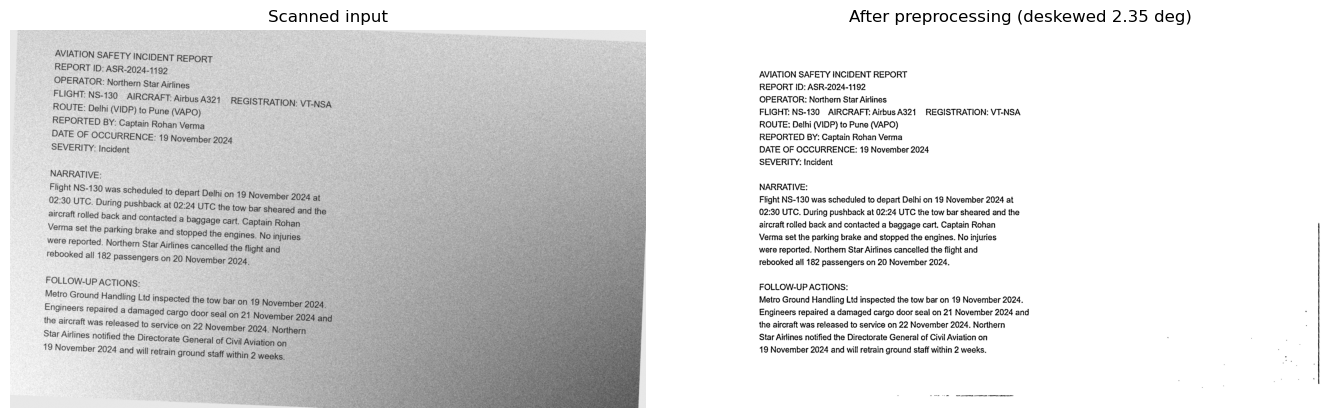

AVIATION SAFETY INCIDENT REPORT
REPORT ID: ASR-2024-1192
OPERATOR: Northern Star Airlines
FLIGHT: NS-130 AIRCRAFT: Airbus A321 REGISTRATION: VT-NSA
ROUTE: Delhi (VIDP) to Pune (VAPO)
REPORTED BY: Captain Rohan Verma
DATE OF OCCURRENCE: 19 November 2024
SEVERITY: Incident

NARRATIVE:
Flight NS-130 was scheduled to depart Delhi on 19 November 2024 at
02:30 UTC. During pushback at 02:24 UTC the tow bar sheared and the
aircraft rolled back and contacted a baggage cart. Captain Rohan
Verma set the parking brake and stopped the engines. No injuries
were reported. Norther Star Airlines cancelled the flight and
rebooked all 182 passengers on 20 November 2024.

FOLLOW-UP ACTIONS:
Metro Ground Handling Ltd inspected the tow bar on 19 November 2024.
Engineers repaired a damaged cargo door seal on 21 November 2024 and
the aircraft was released to service on 22 November 2024. Northern
Star Airlines notified the Directorate General of Civil Aviation on
19 November 2024 and will retrain ground staff 

In [14]:
ocr_rows = []
for name in ["incident_scan_1.png", "incident_scan_2.jpg"]:
    gt = (ROOT / "gold" / f"{Path(name).stem}_groundtruth.txt").read_text()
    clean = preprocess_and_ocr(ROOT / "sample_data" / name)
    raw = preprocess_and_ocr(ROOT / "sample_data" / name, raw=True)
    ocr_rows.append({"scan": name, "detected skew (deg)": round(clean["angle"], 2),
                     "char accuracy - raw Tesseract": round(char_accuracy(raw["text"], gt), 4),
                     "char accuracy - with preprocessing": round(char_accuracy(clean["text"], gt), 4)})
display(pd.DataFrame(ocr_rows))

res_scan = preprocess_and_ocr(ROOT / "sample_data/incident_scan_2.jpg")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].imshow(cv2.imread(str(ROOT / "sample_data/incident_scan_2.jpg"), 0), cmap="gray"); axes[0].set_title("Scanned input")
axes[1].imshow(res_scan["processed"], cmap="gray"); axes[1].set_title(f"After preprocessing (deskewed {res_scan['angle']:.2f} deg)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()
print(res_scan["text"])

## Stage 1 — Text normalisation
Header fields stay one per line; hard-wrapped narrative lines are joined into paragraphs (otherwise names such as *Directorate General of Civil / Aviation* are split by a line break).

In [15]:
# Labels evaluated against the gold standard. Everything else (CARDINAL, DURATION, ...)
# is still shown in the annotated output but is out of schema.
SCHEMA_LABELS = ["PERSON", "ORG", "GPE", "DATE", "TIME", "REPORT_ID", "FLIGHT_NO",
                 "REGISTRATION", "AIRCRAFT_TYPE", "AIRPORT_CODE", "HAZARD", "SEVERITY"]
DOMAIN_LABELS = ["REPORT_ID", "FLIGHT_NO", "REGISTRATION", "AIRCRAFT_TYPE",
                 "AIRPORT_CODE", "HAZARD", "SEVERITY", "TIME"]
STATUS_OBJECTS = {"service", "operations", "operation"}   # 'returned to service' = status, not a relation

_FIELD_LINE = re.compile(r"^[A-Z][A-Z /&().-]{1,40}:\s*\S")      # "OPERATOR: Skyline ..."
_SECTION_HEADER = re.compile(r"^[A-Z][A-Z /&-]{2,40}:\s*$")       # "NARRATIVE:"
_TITLE_LINE = re.compile(r"^[A-Z0-9 /&-]{8,}$")                    # "AVIATION SAFETY ..."


def normalise_text(text: str) -> str:
    """Keep header/field lines intact; join hard-wrapped narrative lines into paragraphs."""
    out, para = [], []

    def flush():
        if para:
            out.append(" ".join(para))
            para.clear()

    for raw in text.replace("\r", "").split("\n"):
        line = re.sub(r"\s+", " ", raw).strip()
        if not line:
            flush()
            if out and out[-1] != "":
                out.append("")
            continue
        if _SECTION_HEADER.match(line) or _FIELD_LINE.match(line) or _TITLE_LINE.match(line):
            flush()
            out.append(line)
        else:
            para.append(line)
    flush()
    return "\n".join(out).strip() + "\n"

## Stage 2 — POS tagging and dependency parsing (spaCy `en_core_web_sm`)
A small custom component forces a sentence boundary at every newline so header fields are never parsed as one sentence. The tagger gives Universal POS + Penn Treebank tags; the parser's dependency arcs drive relation and event extraction later.

In [16]:
def newline_sentences(doc: Doc) -> Doc:
    """Force a sentence boundary after every newline so header fields never merge
    with each other or with the narrative (runs before the parser)."""
    for i, tok in enumerate(doc[:-1]):
        if "\n" in tok.text or "\n" in tok.whitespace_:
            doc[i + 1].is_sent_start = True
    return doc


if not Language.has_factory("newline_sentences"):
    Language.component("newline_sentences", func=newline_sentences)


@lru_cache(maxsize=1)
def get_nlp():
    nlp = spacy.load("en_core_web_sm")
    nlp.add_pipe("newline_sentences", before="parser")
    return nlp

## Stage 3 — Hybrid named-entity recognition
* **Statistical layer** — spaCy NER for PERSON, ORG, GPE, DATE.
* **Domain layer** — regular expressions for codes the statistical model has never seen: `REPORT_ID`, `FLIGHT_NO`, `REGISTRATION`, `AIRCRAFT_TYPE`, `AIRPORT_CODE` (ICAO), UTC `TIME`, `SEVERITY`, full calendar `DATE`s; a lexicon of safety-occurrence terms (`HAZARD`) drawn from general ICAO occurrence categories; and *title + name* patterns ("Captain Meera Nair" → PERSON "Meera Nair").
* **Merge** — regex matches are aligned to token spans with `doc.char_span(..., alignment_mode="expand")` and merged with `filter_spans`; domain spans win on overlap.
* **Clean-up** — durations ("30 days") relabelled `DURATION` (out of schema); document-title line ignored; **document-level label propagation**: a name written as `City (ICAO)` is a place, so every other mention of it is re-labelled GPE (fixes spaCy tagging *Hyderabad* as ORG).
* **Validation** — registrations are checked against ICAO nationality prefixes, flagging OCR confusions like `VT-NSA → VI-NSA`.

In [17]:
DOMAIN_PATTERNS = [
    ("REPORT_ID", re.compile(r"\b[A-Z]{3}-\d{4}-\d{3,5}\b")),
    ("FLIGHT_NO", re.compile(r"\b[A-Z]{2}-\d{2,4}\b")),
    ("REGISTRATION", re.compile(r"\b[A-Z0-9]{2}-[A-Z]{3}\b")),
    ("AIRCRAFT_TYPE", re.compile(
        r"\b(?:Airbus A3[0-9]{2}(?:neo|ceo)?|Boeing 7[0-9]7(?:-[0-9]00(?:ER)?)?|"
        r"ATR (?:42|72)(?:-[0-9]00)?|Embraer E1[79]5|Bombardier Q400|Dash 8(?:-400)?)\b")),
    ("AIRPORT_CODE", re.compile(r"(?<=\()[A-Z]{4}(?=\))")),
    ("DATE", re.compile(r"\b\d{1,2} (?:January|February|March|April|May|June|July|August|"
                        r"September|October|November|December) \d{4}\b")),
    ("TIME", re.compile(r"\b(?:[01]\d|2[0-3]):[0-5]\d ?(?:UTC|Z|IST|LT|hrs)\b")),
    ("SEVERITY", re.compile(r"(?<=SEVERITY: )(?:Serious Incident|Incident|Accident|Occurrence)\b")),
]

# Safety-occurrence vocabulary, taken from general ICAO/CAST occurrence categories
# (wildlife, turbulence, system failures, ground handling, emergency phraseology).
HAZARD_TERMS = [
    r"bird strike", r"wildlife strike", r"(?:severe|moderate|clear air) turbulence",
    r"wind ?shear", r"hydraulic (?:pressure )?(?:warning|failure|leak)", r"engine (?:failure|fire)",
    r"fire warning", r"smoke (?:warning|in the cabin)", r"abnormal vibration", r"tail strike",
    r"runway (?:excursion|incursion)", r"tow ?bar (?:sheared|failure|disconnect(?:ion)?)",
    r"(?:rapid )?decompression", r"stall warning", r"TCAS RA", r"(?:minor|serious|fatal) injuries",
    r"PAN-PAN", r"MAYDAY",
]
HAZARD_RE = re.compile(r"\b(?:" + "|".join(sorted(HAZARD_TERMS, key=len, reverse=True)) + r")\b",
                       re.IGNORECASE)

# Two-letter ICAO nationality prefixes used to sanity-check registrations (catches OCR
# confusions such as VT-NSA -> VI-NSA).
VALID_REG_PREFIXES = {"VT", "HS", "JA", "HL", "EI", "OO", "PH", "EC", "SE", "OY", "LN", "OH",
                      "CS", "TC", "VH", "ZK", "ZS", "CC", "LV", "PR", "PT", "XA", "HZ", "AP",
                      "EP", "SU", "ET", "5Y", "9V", "9M", "A6", "A7", "B-"}

TITLES = ["First Officer", "Senior First Officer", "Captain", "Capt.", "Purser",
          "Cabin Supervisor", "Flight Engineer", "Engineer", "Dispatcher", "Inspector"]
_TITLE_NAME_RE = re.compile(
    r"\b(?:" + "|".join(re.escape(t) for t in sorted(TITLES, key=len, reverse=True)) + r")"
    r"\s+((?:[A-Z][a-z]+)(?:\s+[A-Z][a-z]+){1,2})\b")

_DURATION_RE = re.compile(r"(?i)\b\d+\s*(?:minutes?|hours?|days?|weeks?|months?|years?)\b")
_CALENDAR_RE = re.compile(r"(?i)\b\d{4}\b|\b(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\b")


def _char_span(doc: Doc, start: int, end: int, label: str) -> Span | None:
    return doc.char_span(start, end, label=label, alignment_mode="expand")


def _custom_spans(doc: Doc) -> list[Span]:
    text = doc.text
    spans = []
    for label, rx in DOMAIN_PATTERNS:
        for m in rx.finditer(text):
            sp = _char_span(doc, m.start(), m.end(), label)
            if sp is not None:
                spans.append(sp)
    for m in HAZARD_RE.finditer(text):
        sp = _char_span(doc, m.start(), m.end(), "HAZARD")
        if sp is not None:
            spans.append(sp)
    for m in _TITLE_NAME_RE.finditer(text):                      # "Captain Meera Nair"
        sp = _char_span(doc, m.start(1), m.end(1), "PERSON")
        if sp is not None:
            spans.append(sp)
    # A FLIGHT_NO pattern can also match a registration-like token; registrations need
    # letters after the hyphen, flight numbers digits, so the two never overlap.
    return filter_spans(spans)


def _overlaps(span: Span, others: list[Span]) -> bool:
    return any(span.start < o.end and o.start < span.end for o in others)


def _strip_title(span: Span) -> Span:
    """'Captain Meera Nair' -> 'Meera Nair'; also drops a leading 'the'."""
    start = span.start
    words = [t.text for t in span]
    for title in sorted(TITLES, key=len, reverse=True):
        tw = title.split()
        if words[: len(tw)] == tw and len(words) > len(tw):
            start = span.start + len(tw)
            break
    if span.doc[start].lower_ == "the" and start + 1 < span.end:
        start += 1
    return Span(span.doc, start, span.end, label=span.label_) if start != span.start else span


def hybrid_ner(doc: Doc) -> Doc:
    """Merge statistical NER with the domain layer; domain spans win on overlap."""
    custom = _custom_spans(doc)
    stat = []
    for ent in doc.ents:
        if _overlaps(ent, custom):
            continue
        label = ent.label_
        if label in ("DATE", "TIME") and _DURATION_RE.search(ent.text) and not (
                label == "DATE" and _CALENDAR_RE.search(ent.text)):
            label = "DURATION"                                   # '30 days', '48 hours'
        elif label == "LOC":
            label = "GPE"
        if label == "PERSON" or label == "ORG":
            ent = _strip_title(Span(doc, ent.start, ent.end, label=label))
        # 'ROUTE:' / 'OPERATOR:' style field keys are sometimes tagged as ORG
        if ent.text.isupper() and label in ("ORG", "GPE", "PERSON") and ent.text.endswith(":"):
            continue
        stat.append(Span(doc, ent.start, ent.end, label=label))

    title_ranges = []
    pos = 0
    for line in doc.text.split("\n"):
        letters = [c for c in line if c.isalpha()]
        if ":" not in line and len(letters) >= 8 and sum(c.isupper() for c in letters) / len(letters) > 0.9:
            title_ranges.append((pos, pos + len(line)))
        pos += len(line) + 1
    stat = [e for e in stat if not any(a <= e.start_char < b for a, b in title_ranges)]
    ents = filter_spans(custom + stat)

    # Document-level label propagation: anything written as "Name (ICAO)" is a place,
    # and every other mention of that name in the document gets the same label.
    places = set()
    for e in ents:
        if e.label_ == "AIRPORT_CODE":
            prev = [x for x in ents if x.end <= e.start - 1 and e.start - x.end <= 2]
            if prev:
                places.add(prev[-1].text)
            else:   # place name not detected at all: take the capitalised token(s) before "("
                i = e.start - 2
                if i >= 0 and doc[i].is_title:
                    places.add(doc[i].text)
    fixed, relabelled, propagated = [], set(), set()
    for e in ents:
        if e.text in places and e.label_ in ("ORG", "PERSON", "NORP", "FAC"):
            fixed.append(Span(doc, e.start, e.end, label="GPE"))
            relabelled.add((e.start_char, e.end_char))
        else:
            fixed.append(e)
    covered = {i for e in fixed for i in range(e.start, e.end)}
    for name in places:
        for m in re.finditer(r"\b" + re.escape(name) + r"\b", doc.text):
            sp = _char_span(doc, m.start(), m.end(), "GPE")
            if sp is not None and not any(i in covered for i in range(sp.start, sp.end)):
                fixed.append(sp)
                propagated.add((sp.start_char, sp.end_char))
                covered.update(range(sp.start, sp.end))
    doc.ents = filter_spans(fixed)
    doc.user_data["domain_spans"] = {(sp.start_char, sp.end_char) for sp in custom}
    doc.user_data["propagated_spans"] = propagated
    doc.user_data["relabelled_spans"] = relabelled
    return doc


def registration_valid(reg: str) -> bool:
    return reg[:2] in VALID_REG_PREFIXES

## Stage 4 — Entity linking (optional)
ORG/PERSON/GPE mentions can be looked up with the Wikidata `wbsearchentities` API. Only an exact label match is accepted, so fictional organisations stay **unlinked rather than wrongly linked**. It needs internet access, is off by default (`run_pipeline(text, link=True)` to enable) and caches results in `linking_cache.json`.

In [18]:
_LINK_CACHE_PATH = ROOT / "linking_cache.json"


def _load_link_cache() -> dict:
    try:
        return json.loads(_LINK_CACHE_PATH.read_text())
    except Exception:
        return {}


def link_to_wikidata(entity_text: str, timeout: float = 5.0) -> tuple[str | None, str]:
    """Return (QID or None, status). Status is 'linked', 'no match' or 'offline'.
    Results are cached in linking_cache.json so repeated runs work offline."""
    cache = _load_link_cache()
    if entity_text in cache:
        qid = cache[entity_text]
        return qid, "linked (cached)" if qid else "no match (cached)"
    try:
        import requests
        resp = requests.get("https://www.wikidata.org/w/api.php", timeout=timeout,
                            params={"action": "wbsearchentities", "search": entity_text,
                                    "language": "en", "format": "json", "limit": 1},
                            headers={"User-Agent": "aviation-incident-ie/1.0 (student lab project)"})
        hits = resp.json().get("search", [])
    except Exception:
        return None, "offline"
    qid = None
    if hits:
        label = hits[0].get("label", "")
        # accept only an exact (case-insensitive) label match: silent rather than wrong
        if label.lower() == entity_text.lower():
            qid = hits[0]["id"]
    cache[entity_text] = qid
    try:
        _LINK_CACHE_PATH.write_text(json.dumps(cache, indent=2, sort_keys=True))
    except Exception:
        pass
    return qid, "linked" if qid else "no match"

In [19]:
def canon(text: str) -> str:
    text = re.sub(r"\s+", " ", text).strip()
    return re.sub(r"^(?:the|a|an)\s+", "", text, flags=re.IGNORECASE)


def _ent_of(tok, doc) -> Span | None:
    for e in doc.ents:
        if e.start <= tok.i < e.end:
            return e
    return None


@dataclass
class DocContext:
    doc: Doc
    flight: str | None = None
    report_id: str | None = None
    occurrence_date: datetime | None = None
    field_ranges: list[tuple[int, int]] = field(default_factory=list)   # char ranges of header lines


def _field_lines(doc: Doc) -> list[tuple[str, int, int]]:
    """Return (normalised key, start_char, end_char) for each 'KEY: value' header line."""
    out, pos = [], 0
    for line in doc.text.split("\n"):
        m = re.match(r"^([A-Z][A-Z /&().-]{1,40}):\s*\S", line)
        if m and not _SECTION_HEADER.match(line):
            out.append((m.group(1).strip(), pos, pos + len(line)))
        pos += len(line) + 1
    return out


FIELD_KEYS = ["REPORT ID", "OPERATOR", "FLIGHT", "AIRCRAFT", "REGISTRATION", "ROUTE",
              "REPORTED BY", "DATE OF OCCURRENCE", "SEVERITY"]


def _match_key(key: str) -> str | None:
    """Fuzzy header-key matching so OCR noise ('REPORTED BV') still maps to a field."""
    hit = difflib.get_close_matches(key.upper(), FIELD_KEYS, n=1, cutoff=0.75)
    return hit[0] if hit else None


def parse_date(text: str) -> datetime | None:
    """Only absolute calendar dates are parsed; durations and vague phrases return None."""
    if not _CALENDAR_RE.search(text):
        return None
    if _DURATION_RE.search(text) and not re.search(r"\b\d{4}\b", text):
        return None
    try:
        return dateparser.parse(text, fuzzy=True, default=datetime(1900, 1, 1))
    except (ValueError, OverflowError):
        return None


def build_context(doc: Doc) -> DocContext:
    ctx = DocContext(doc=doc)
    for key, s, e in _field_lines(doc):
        ctx.field_ranges.append((s, e))
        k = _match_key(key)
        ents = [x for x in doc.ents if x.start_char >= s and x.end_char <= e]
        if k == "FLIGHT":
            f = [x for x in ents if x.label_ == "FLIGHT_NO"]
            ctx.flight = ctx.flight or (f[0].text if f else None)
        elif k == "REPORT ID":
            r = [x for x in ents if x.label_ == "REPORT_ID"]
            ctx.report_id = r[0].text if r else ctx.report_id
        elif k == "DATE OF OCCURRENCE":
            d = [x for x in ents if x.label_ == "DATE"]
            ctx.occurrence_date = parse_date(d[0].text) if d else None
    if ctx.flight is None:
        f = [x for x in doc.ents if x.label_ == "FLIGHT_NO"]
        ctx.flight = f[0].text if f else None
    return ctx


def _in_header(ctx: DocContext, tok_or_span) -> bool:
    c = tok_or_span.idx if hasattr(tok_or_span, "idx") else tok_or_span.start_char
    return any(s <= c < e for s, e in ctx.field_ranges)

## Stage 5 — Relation extraction
1. **Header field-linking** — the `KEY: value` lines give typed triples: `(report, CONCERNS_FLIGHT, flight)`, `(flight, OPERATED_BY, org)`, `(flight, ORIGIN/DESTINATION, place)`, `(place, AIRPORT_CODE, ICAO)`, … Keys are matched fuzzily so OCR noise in a key still works.
2. **Dependency-parse SVO rules** on the narrative — for every verb: subject (`nsubj`, or the `agent` of a passive), objects (`dobj`/`attr`) and prepositional arguments (`to/from/at/with…`) → `(subject, LEMMA[_PREP], object)`. Subjects are inherited through coordination (*inspected … and replaced …*) and control verbs (*was scheduled to depart*). Dates/times are left to the event stage; quantities ("162 passengers") are skipped.
3. **Rule-based coreference** — *the aircraft / the flight* → the report's flight number; *Engineers from AeroTech MRO Services* → the organisation.

In [20]:
VEHICLE_NOUNS = {"aircraft", "flight", "airplane", "aeroplane", "plane", "jet"}
AGENT_NOUNS = {"engineer", "technician", "team", "staff", "crew", "inspector", "personnel",
               "mechanic", "official", "investigator"}
SUBJ_DEPS = {"nsubj", "nsubjpass"}
OBJ_DEPS = {"dobj", "attr", "oprd"}
ARG_PREPS = {"to", "from", "at", "into", "with", "onto"}


def _resolve_arg(tok, ctx: DocContext, role: str) -> tuple[str | None, bool]:
    """Map a syntactic argument head to (canonical text, is_entity).

    - inside a schema entity                -> the entity text
    - 'the aircraft' / 'the flight'          -> document flight number (rule-based coref)
    - 'Engineers from AeroTech MRO Services' -> the organisation
    - otherwise (objects only)               -> head-noun phrase without determiner
    """
    doc = ctx.doc
    ent = _ent_of(tok, doc)
    if ent is not None and ent.label_ in SCHEMA_LABELS:
        return canon(ent.text), True
    if tok.lemma_.lower() in VEHICLE_NOUNS and ctx.flight:
        return ctx.flight, True
    if tok.lemma_.lower() in AGENT_NOUNS:
        for prep in (c for c in tok.children if c.dep_ == "prep" and c.lower_ == "from"):
            for p in prep.children:
                pe = _ent_of(p, doc)
                if p.dep_ == "pobj" and pe is not None and pe.label_ == "ORG":
                    return canon(pe.text), True
    if role == "subj":
        return None, False
    mods = [c for c in tok.lefts if c.dep_ in ("amod", "compound")]
    phrase = " ".join([m.text for m in mods] + [tok.text])
    return canon(phrase), False


def _subjects(verb) -> list:
    subs = [c for c in verb.children if c.dep_ in SUBJ_DEPS]
    if not subs and verb.dep_ == "conj":                 # "...inspected X and replaced Y"
        return _subjects(verb.head)
    if not subs and verb.dep_ in ("xcomp", "advcl") and verb.head.pos_ in ("VERB", "AUX"):
        return _subjects(verb.head)                      # "was scheduled to depart"
    return subs


def _expand_conj(tok) -> list:
    return [tok] + [c for c in tok.conjuncts]


def _is_negated(verb) -> bool:
    if any(c.dep_ == "neg" for c in verb.children):
        return True
    for s in (c for c in verb.children if c.dep_ in SUBJ_DEPS):
        if any(d.dep_ == "det" and d.lower_ == "no" for d in s.children):
            return True
    return False


def extract_relations(ctx: DocContext) -> pd.DataFrame:
    doc = ctx.doc
    rows = []

    # (a) header field-linking ---------------------------------------------------
    for key, s, e in _field_lines(doc):
        k = _match_key(key)
        ents = [x for x in doc.ents if x.start_char >= s and x.end_char <= e]
        by = {}
        for x in ents:
            by.setdefault(x.label_, []).append(canon(x.text))
        fl = ctx.flight
        rid = ctx.report_id
        if k == "FLIGHT":
            if rid and fl:
                rows.append((rid, "CONCERNS_FLIGHT", fl, "field"))
            for reg in by.get("REGISTRATION", []):
                if fl:
                    rows.append((fl, "USES_AIRCRAFT", reg, "field"))
                for t in by.get("AIRCRAFT_TYPE", []):
                    rows.append((reg, "AIRCRAFT_TYPE", t, "field"))
        elif k == "OPERATOR" and fl:
            for o in by.get("ORG", []):
                rows.append((fl, "OPERATED_BY", o, "field"))
        elif k == "ROUTE" and fl:
            places = by.get("GPE", [])
            if places:
                rows.append((fl, "ORIGIN", places[0], "field"))
            if len(places) > 1:
                rows.append((fl, "DESTINATION", places[-1], "field"))
        elif k == "REPORTED BY" and rid:
            for p in by.get("PERSON", []):
                rows.append((rid, "REPORTED_BY", p, "field"))
        elif k == "DATE OF OCCURRENCE" and rid:
            for d in by.get("DATE", []):
                rows.append((rid, "OCCURRED_ON", d, "field"))
        elif k == "SEVERITY" and rid:
            for sv in by.get("SEVERITY", []):
                rows.append((rid, "SEVERITY", sv, "field"))
    # "City (ICAO)" anywhere in the document
    ents = list(doc.ents)
    for i, e in enumerate(ents):
        if e.label_ == "AIRPORT_CODE" and i > 0 and ents[i - 1].label_ == "GPE" \
                and e.start_char - ents[i - 1].end_char <= 2:
            rows.append((canon(ents[i - 1].text), "AIRPORT_CODE", e.text, "field"))

    # (b) dependency-parse SVO rules on narrative sentences ------------------------
    for sent in doc.sents:
        if _in_header(ctx, sent):
            continue
        for verb in sent:
            if verb.pos_ != "VERB" or _is_negated(verb):
                continue
            prt = next((c.text.upper() for c in verb.children if c.dep_ == "prt"), "")
            base = verb.lemma_.upper() + (f"_{prt}" if prt else "")
            subj_toks = _subjects(verb)
            pairs = []
            agent = next((c for c in verb.children if c.dep_ == "agent"), None)
            for s in subj_toks:
                if s.dep_ == "nsubjpass":
                    if agent is None:
                        continue          # passive without agent: no grounded subject
                    for a in (c for c in agent.children if c.dep_ == "pobj"):
                        pairs.append((a, [s], base))
                    continue
                objs = [c for c in verb.children if c.dep_ in OBJ_DEPS]
                for o in objs:
                    pairs.append((s, _expand_conj(o), base))
                for p in (c for c in verb.children if c.dep_ == "prep" and c.lower_ in ARG_PREPS):
                    for po in (c for c in p.children if c.dep_ == "pobj"):
                        pe = _ent_of(po, doc)
                        if pe is not None and pe.label_ in ("DATE", "TIME", "DURATION"):
                            continue      # temporal modifiers belong to events, not relations
                        if any(c.dep_ == "nummod" for c in po.children):
                            continue      # '162 passengers' is a quantity, not a participant
                        pairs.append((s, _expand_conj(po), f"{base}_{p.text.upper()}"))
            for s, objs, label in pairs:
                subj, s_is_ent = _resolve_arg(s, ctx, "subj")
                if not subj or not s_is_ent:
                    continue
                for o in objs:
                    obj, _ = _resolve_arg(o, ctx, "obj")
                    if obj and obj.lower() in STATUS_OBJECTS:
                        continue
                    if obj and obj != subj:
                        rows.append((subj, label, obj, "narrative"))
    df = pd.DataFrame(rows, columns=["subject", "relation", "object", "source"]).drop_duplicates()
    return df.reset_index(drop=True)

## Stage 6 — Event extraction
A trigger lexicon maps verb lemmas to event types (depart → DEPARTURE, divert → DIVERSION, inspect → INSPECTION, …) with context checks (*returned **to service*** → RETURN_TO_SERVICE vs *returned to Chennai* → RETURN; *suffered **injuries*** → INJURY). **Negation** ("No injuries were reported") and **modality** ("was scheduled to depart" → PLANNED_DEPARTURE) are handled. Each event takes the DATE/TIME expressions that the dependency tree attaches to *its own* verb.

In [21]:
TRIGGERS = {
    "depart": "DEPARTURE", "takeoff": "DEPARTURE", "observe": "HAZARD_DETECTED",
    "detect": "HAZARD_DETECTED", "encounter": "HAZARD_ENCOUNTER", "suffer": "HAZARD_ENCOUNTER",
    "strike": "HAZARD_ENCOUNTER", "shear": "EQUIPMENT_FAILURE", "fail": "EQUIPMENT_FAILURE",
    "malfunction": "EQUIPMENT_FAILURE", "declare": "EMERGENCY_DECLARED", "request": "REQUEST",
    "divert": "DIVERSION", "return": "RETURN", "land": "LANDING", "inspect": "INSPECTION",
    "examine": "INSPECTION", "find": "FINDING", "replace": "REPAIR", "repair": "REPAIR",
    "rectify": "REPAIR", "release": "RETURN_TO_SERVICE", "resume": "RETURN_TO_SERVICE",
    "notify": "NOTIFICATION", "file": "NOTIFICATION", "inform": "CREW_REPORT",
    "report": "CREW_REPORT", "open": "INVESTIGATION", "investigate": "INVESTIGATION",
    "submit": "REPORT_SUBMISSION", "complete": "TRAINING", "retrain": "TRAINING",
    "train": "TRAINING", "shut": "ENGINE_SHUTDOWN", "stop": "ENGINE_SHUTDOWN",
    "cancel": "CANCELLATION", "rebook": "REBOOKING", "disembark": "DISEMBARKATION",
    "evacuate": "EVACUATION", "contact": "COLLISION", "collide": "COLLISION",
    "hit": "COLLISION", "meet": "MEDICAL_RESPONSE", "review": "REVIEW", "issue": "BULLETIN_ISSUED",
}
PLANNING_VERBS = {"schedule", "plan", "expect", "intend"}


def _subtree_text(tok) -> str:
    return " ".join(t.lower_ for t in tok.subtree)


def _event_type(verb, ctx: DocContext) -> str | None:
    lemma = verb.lemma_.lower()
    etype = TRIGGERS.get(lemma)
    if etype is None:
        return None
    # everything to the right of the trigger inside its own clause (objects, preps,
    # particles; also catches mis-attached phrases such as 'to service' parsed as advcl)
    objs = " ".join(_subtree_text(c) for c in verb.rights
                    if c.dep_ not in ("conj", "cc", "punct"))
    subj = " ".join(_subtree_text(s) for s in _subjects(verb))
    if lemma in ("suffer", "encounter") and "injur" in objs:
        return "INJURY"
    if lemma == "return":
        return "RETURN_TO_SERVICE" if "service" in objs else "RETURN"
    if lemma == "release" and "service" not in objs:
        return None
    if lemma == "complete" and "training" not in objs:
        return None
    if lemma == "stop" and "engine" not in objs:
        return None
    if lemma == "shut" and "engine" not in objs:
        return None
    if lemma == "meet" and "medical" not in subj:
        return None
    if lemma == "issue" and not re.search(r"bulletin|notice|directive|advisory", objs):
        return None
    if lemma == "open" and "investigation" not in objs:
        return None
    if lemma == "report":
        if not any(_ent_of(s, ctx.doc) is not None and _ent_of(s, ctx.doc).label_ == "PERSON"
                   for s in _subjects(verb)):
            return None
    if lemma == "file" and not re.search(r"report|notification", objs):
        return None
    if etype == "DEPARTURE" and verb.dep_ == "xcomp" and verb.head.lemma_.lower() in PLANNING_VERBS:
        return "PLANNED_DEPARTURE"
    return etype


def _owning_verb(tok):
    """Climb the dependency tree from tok to the first VERB above it."""
    cur = tok.head
    while cur.pos_ not in ("VERB",) and cur.head is not cur:
        cur = cur.head
    return cur if cur.pos_ == "VERB" else None


def extract_events(ctx: DocContext) -> pd.DataFrame:
    doc = ctx.doc
    rows = []
    reference = ctx.occurrence_date               # discourse reference date
    order = 0
    for sent in doc.sents:
        if _in_header(ctx, sent):
            continue
        temporal = [e for e in sent.ents if e.label_ in ("DATE", "TIME", "DURATION")]
        owner = {e: _owning_verb(e.root) for e in temporal}
        for verb in sent:
            if verb.pos_ != "VERB" or _is_negated(verb):
                continue
            etype = _event_type(verb, ctx)
            if etype is None:
                continue
            owned = [e for e, v in owner.items() if v is not None and v.i == verb.i]
            dates = [e for e in owned if e.label_ == "DATE" and parse_date(e.text)]
            times = [e for e in owned if e.label_ == "TIME"]
            durations = [e for e in owned if e.label_ == "DURATION"]
            hhmm_pre = bool(times)
            date_txt = dates[0].text if dates else ""
            time_txt = times[0].text if times else ""
            if dates:
                date = parse_date(dates[0].text)
                anchor = "explicit"
                reference = date
            elif durations:
                date, anchor = None, f"unresolved (duration: {durations[0].text})"
            elif reference is not None:
                date = reference
                anchor = "time explicit, date inherited" if hhmm_pre else "inherited from discourse"
            else:
                date, anchor = None, "unresolved"
            hhmm = re.search(r"\d{2}:\d{2}", time_txt).group(0) if time_txt else None
            args = [canon(" ".join(t.text for t in s.subtree)) for s in _subjects(verb)]
            order += 1
            rows.append({
                "order": order, "event_type": etype, "trigger": verb.text,
                "date": date.strftime("%Y-%m-%d") if date else None, "time": hhmm,
                "date_text": date_txt, "time_text": time_txt, "anchoring": anchor,
                "participants": ", ".join(args), "sentence": sent.text.strip(),
            })
    return pd.DataFrame(rows, columns=["order", "event_type", "trigger", "date", "time",
                                       "date_text", "time_text", "anchoring", "participants",
                                       "sentence"])

## Stage 7 — Temporal ordering
* Only absolute calendar dates are parsed; durations ("within 30 days") leave the event **unresolved** instead of inventing a date.
* Events with no date of their own inherit the **discourse reference date** (the last explicit date, starting from *DATE OF OCCURRENCE*); clock times are never invented.
* Events are sorted by (date, clock time, mention order); the order is stored as a NetworkX **precedence DAG** whose layers are groups of events that cannot be ordered against each other.

In [22]:
def _str_or_none(v):
    return v if isinstance(v, str) else None


def order_events(events: pd.DataFrame) -> tuple[pd.DataFrame, nx.DiGraph]:
    """Sort events chronologically and build a precedence DAG.

    Events without an explicit clock time take the most recent explicit time already
    mentioned for the same date (narrative-order assumption) only as a sort key; they are never shown
    with an invented time. Unresolved events are kept and placed last.
    """
    ev = events.copy()
    last_time_on: dict[str, str] = {}      # most recent explicit clock time seen per date
    eff = []
    for _, r in ev.iterrows():
        d = r["date"] if isinstance(r["date"], str) else None
        t = r["time"] if isinstance(r["time"], str) else None
        if d and t:
            last_time_on[d] = t
        eff.append(t or (last_time_on.get(d) if d else None) or "00:00")
    ev["sort_time"] = eff
    resolved = ev[ev["date"].notna()].sort_values(["date", "sort_time", "order"], kind="stable")
    unresolved = ev[ev["date"].isna()]
    ordered = pd.concat([resolved, unresolved]).reset_index(drop=True)
    ordered.insert(0, "rank", range(1, len(ordered) + 1))

    g = nx.DiGraph()
    for _, r in ordered.iterrows():
        g.add_node(int(r["order"]), label=f"{r['event_type']}", date=_str_or_none(r["date"]),
                   time=_str_or_none(r["time"]), rank=int(r["rank"]))
    groups = []
    for _, r in ordered[ordered["date"].notna()].iterrows():
        key = (r["date"], r["sort_time"])
        if groups and groups[-1][0] == key:
            groups[-1][1].append(int(r["order"]))
        else:
            groups.append((key, [int(r["order"])]))
    for (k1, a), (k2, b) in zip(groups, groups[1:]):
        for u in a:
            for v in b:
                g.add_edge(u, v, relation="BEFORE")
    assert nx.is_directed_acyclic_graph(g)
    return ordered.drop(columns=["sort_time"]), g

## Stage 8 — Knowledge graph and end-to-end `run_pipeline()`

In [23]:
NODE_TYPE_OF = {"PERSON": "Person", "ORG": "Organisation", "GPE": "Place", "DATE": "Date",
                "TIME": "Time", "REPORT_ID": "Report", "FLIGHT_NO": "Flight",
                "REGISTRATION": "Aircraft", "AIRCRAFT_TYPE": "Aircraft type",
                "AIRPORT_CODE": "Airport code", "HAZARD": "Hazard", "SEVERITY": "Severity"}


def build_knowledge_graph(entities: pd.DataFrame, relations: pd.DataFrame,
                          events: pd.DataFrame | None = None, flight: str | None = None
                          ) -> nx.MultiDiGraph:
    g = nx.MultiDiGraph()
    label_of = {}
    for _, e in entities.iterrows():
        label_of.setdefault(e["text"], e["label"])
    for _, r in relations.iterrows():
        for n in (r["subject"], r["object"]):
            if n not in g:
                lab = label_of.get(n)
                g.add_node(n, type=NODE_TYPE_OF.get(lab, "Concept"))
        g.add_edge(r["subject"], r["object"], relation=r["relation"], source=r["source"])
    if events is not None and flight:
        if flight not in g:
            g.add_node(flight, type="Flight")
        for _, ev in events.iterrows():
            node = f"{ev['event_type']} #{ev['order']}"
            g.add_node(node, type="Event", date=ev["date"] or "unresolved")
            g.add_edge(flight, node, relation="HAS_EVENT", source="event")
            if ev["date"]:
                d = datetime.strptime(ev["date"], "%Y-%m-%d").strftime("%-d %B %Y")
                if d not in g:
                    g.add_node(d, type="Date")
                g.add_edge(node, d, relation="ON_DATE", source="event")
    return g

In [24]:
@dataclass
class PipelineResult:
    text: str
    doc: Doc
    context: DocContext
    pos: pd.DataFrame
    entities: pd.DataFrame
    relations: pd.DataFrame
    events: pd.DataFrame
    timeline: pd.DataFrame
    temporal_graph: nx.DiGraph
    knowledge_graph: nx.MultiDiGraph


def pos_table(doc: Doc) -> pd.DataFrame:
    return pd.DataFrame([{
        "i": t.i, "token": t.text, "lemma": t.lemma_, "upos": t.pos_, "tag": t.tag_,
        "dep": t.dep_, "head": t.head.text,
        "entity": f"{t.ent_iob_}-{t.ent_type_}" if t.ent_type_ else "O",
    } for t in doc if not t.is_space])


def _source_of(e: Span) -> str:
    ud = e.doc.user_data
    key = (e.start_char, e.end_char)
    if key in ud.get("domain_spans", ()):
        return "domain rule"
    if key in ud.get("propagated_spans", ()):
        return "label propagation"
    if key in ud.get("relabelled_spans", ()):
        return "spaCy + relabel"
    return "spaCy"


def entity_table(doc: Doc, link: bool = False) -> pd.DataFrame:
    rows = []
    for e in doc.ents:
        row = {"text": canon(e.text), "label": e.label_, "start_char": e.start_char,
               "end_char": e.end_char,
               "source": _source_of(e),
               "in_schema": e.label_ in SCHEMA_LABELS, "note": ""}
        if e.label_ == "REGISTRATION" and not registration_valid(e.text):
            row["note"] = "check: unknown nationality prefix (possible OCR error)"
        if link and e.label_ in ("ORG", "GPE", "PERSON"):
            qid, status = link_to_wikidata(canon(e.text))
            row["wikidata"] = qid or ""
            row["link_status"] = status
        rows.append(row)
    return pd.DataFrame(rows)


def run_pipeline(text: str, link: bool = False) -> PipelineResult:
    norm = normalise_text(text)
    doc = hybrid_ner(get_nlp()(norm))
    ctx = build_context(doc)
    pos = pos_table(doc)
    entities = entity_table(doc, link=link)
    relations = extract_relations(ctx)
    events = extract_events(ctx)
    timeline, tgraph = order_events(events)
    kg = build_knowledge_graph(entities, relations)
    return PipelineResult(norm, doc, ctx, pos, entities, relations, events, timeline, tgraph, kg)


def conll_annotations(doc: Doc) -> str:
    """Token-level annotated text: TOKEN  UPOS  TAG  DEP  HEAD  BIO-entity (one per line)."""
    lines = ["# token\tupos\ttag\tdep\thead\tentity"]
    for sent in doc.sents:
        for t in sent:
            if t.is_space:
                continue
            ent = f"{t.ent_iob_}-{t.ent_type_}" if t.ent_type_ else "O"
            lines.append(f"{t.text}\t{t.pos_}\t{t.tag_}\t{t.dep_}\t{t.head.i - sent.start + 1}\t{ent}")
        lines.append("")
    return "\n".join(lines)


ENT_COLORS = {
    "PERSON": "#f7c6c7", "ORG": "#c6dbef", "GPE": "#c7e9c0", "DATE": "#fdd0a2", "TIME": "#fde0ef",
    "REPORT_ID": "#d9d9d9", "FLIGHT_NO": "#bcbddc", "REGISTRATION": "#9ecae1",
    "AIRCRAFT_TYPE": "#a1d99b", "AIRPORT_CODE": "#e5f5e0", "HAZARD": "#fc9272",
    "SEVERITY": "#fdae6b", "DURATION": "#eeeeee", "CARDINAL": "#f0f0f0",
}


def annotated_html(doc: Doc) -> str:
    from spacy import displacy
    return displacy.render(doc, style="ent", page=False,
                           options={"colors": ENT_COLORS})

### Plotting helpers (timeline, temporal DAG, knowledge graph)

In [34]:
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER = "#a3a29c"

# knowledge-graph node type -> fixed categorical slot (never cycled)
TYPE_COLOR = {
    "Flight": SERIES[0], "Organisation": SERIES[1], "Place": SERIES[2], "Date": SERIES[3],
    "Time": SERIES[3], "Person": SERIES[4], "Aircraft": SERIES[5], "Aircraft type": SERIES[5],
    "Report": SERIES[6], "Hazard": SERIES[7],
}
LEGEND_ORDER = ["Flight", "Organisation", "Place", "Date", "Person", "Aircraft", "Report", "Hazard", "Other"]

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
})


def _fmt_date(d: str) -> str:
    return datetime.strptime(d, "%Y-%m-%d").strftime("%d %b").lstrip("0")


# ------------------------------------------------------------------ timeline
def timeline_figure(timeline: pd.DataFrame, title: str = "Event timeline"):
    """Milestone timeline. X is chronological rank (even spacing keeps same-day events
    readable); each stem carries the date and, when stated, the clock time. Stem heights
    cycle through six levels so neighbouring labels never collide. Unresolved events are
    fanned out after the axis end and labelled 'date unresolved' instead of dropped."""
    n = len(timeline)
    fig, ax = plt.subplots(figsize=(max(9, 0.95 * n + 2), 4.6))
    levels = [1.0, -1.0, 2.0, -2.0, 3.0, -3.0]
    resolved = timeline[timeline["date"].apply(lambda v: isinstance(v, str))]
    unresolved = timeline[~timeline.index.isin(resolved.index)]
    xs = list(range(len(resolved)))
    gap = 1.2
    ux = [len(resolved) - 1 + gap + i for i in range(len(unresolved))]
    ax.axhline(0, color=INK2, lw=1.2, zorder=1)
    if ux:
        ax.plot([xs[-1] + 0.3 if xs else 0, ux[-1] + 0.3], [0, 0], color=MUTED, lw=1.2, ls=(0, (3, 3)))

    # shade alternate calendar days so date groups read at a glance
    prev, start = None, 0
    spans = []
    for x, (_, r) in zip(xs, resolved.iterrows()):
        if r["date"] != prev:
            if prev is not None:
                spans.append((start, x - 1, prev))
            prev, start = r["date"], x
    if prev is not None:
        spans.append((start, xs[-1], prev))
    for i, (a, b, d) in enumerate(spans):
        if i % 2 == 0:
            ax.axvspan(a - 0.5, b + 0.5, color="#f1f0ec", zorder=0, lw=0)
        ax.text((a + b) / 2, -3.85, _fmt_date(d), ha="center", va="top", color=INK2, fontsize=8.5,
                fontweight="bold")

    def stem(x, lvl, r, color, unresolved_flag=False):
        ax.vlines(x, 0, lvl, color=color, lw=1.5, zorder=2)
        ax.scatter([x], [0], s=46, color=color, zorder=3, edgecolor=SURFACE, linewidth=1.5)
        when = "date unresolved" if unresolved_flag else (
            f"{_fmt_date(r['date'])}" + (f" {r['time']}" if isinstance(r["time"], str) else ""))
        label = r["event_type"].replace("_", " ").lower()
        va = "bottom" if lvl > 0 else "top"
        ax.text(x, lvl + (0.08 if lvl > 0 else -0.08), f"{label}\n{when}", ha="center", va=va,
                fontsize=7.8, color=INK, linespacing=1.15)

    for i, (x, (_, r)) in enumerate(zip(xs, resolved.iterrows())):
        stem(x, levels[i % 6], r, SERIES[0])
    for i, (x, (_, r)) in enumerate(zip(ux, unresolved.iterrows())):
        stem(x, levels[(len(xs) + i) % 6], r, OTHER, unresolved_flag=True)

    ax.set_ylim(-4.3, 4.1)
    ax.set_xlim(-0.8, (ux[-1] if ux else xs[-1] if xs else 0) + 0.8)
    ax.axis("off")
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    fig.tight_layout()
    return fig


# ------------------------------------------------------------------ temporal DAG
def temporal_dag_figure(g: nx.DiGraph, title: str = "Temporal precedence DAG"):
    """Left-to-right layering: each column is one (date, time) group of simultaneous or
    unordered events; arrows mean BEFORE. Unresolved events sit in a separate final column."""
    layer = {}
    for n in nx.topological_sort(g):
        preds = list(g.predecessors(n))
        layer[n] = 0 if not preds else max(layer[p] for p in preds) + 1
    unresolved = [n for n, d in g.nodes(data=True) if not d.get("date")]
    maxl = max([layer[n] for n in g if n not in unresolved], default=0)
    for n in unresolved:
        layer[n] = maxl + 1
    cols = {}
    for n, l in layer.items():
        cols.setdefault(l, []).append(n)
    pos = {}
    for l, ns in cols.items():
        ns.sort(key=lambda x: g.nodes[x]["rank"])
        for i, n in enumerate(ns):
            pos[n] = (l, -(i - (len(ns) - 1) / 2))
    width = max(8, 1.25 * (max(cols) + 1))
    height = max(3.2, 0.9 * max(len(v) for v in cols.values()) + 1.2)
    fig, ax = plt.subplots(figsize=(width, height))
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color=MUTED, arrows=True, arrowsize=10, width=0.9,
                           node_size=1400, connectionstyle="arc3,rad=0.04")
    colors = [OTHER if n in unresolved else SERIES[0] for n in g]
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color=colors, node_size=260, edgecolors=SURFACE, linewidths=1.5)
    for n, (x, y) in pos.items():
        d = g.nodes[n]
        when = "unresolved" if not d.get("date") else _fmt_date(d["date"]) + (f" {d['time']}" if d.get("time") else "")
        ax.text(x, y - 0.24, f"{d['label'].replace('_', ' ').lower()}\n{when}", ha="center", va="top",
                fontsize=7, color=INK, linespacing=1.1)
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.axis("off")
    ys = [p[1] for p in pos.values()] or [0]
    ax.set_ylim(min(ys) - 0.75, max(ys) + 0.4)
    ax.set_xlim(-0.6, max(cols) + 0.6)
    fig.tight_layout()
    return fig


# ------------------------------------------------------------------ knowledge graph
def _wrap(s: str, w: int = 16) -> str:
    return "\n".join(textwrap.wrap(s, w)) or s


def kg_layout(g: nx.MultiDiGraph, seed: int = 7) -> dict:
    """Kamada-Kawai per connected component; the largest component fills the left of
    the canvas and smaller fragments are stacked in a column on the right."""
    simple = nx.Graph(g.to_undirected())
    comps = sorted(nx.connected_components(simple), key=len, reverse=True)
    pos = {}
    if not comps:
        return pos
    main = simple.subgraph(comps[0])
    p = nx.kamada_kawai_layout(main) if len(main) > 2 else nx.spring_layout(main, seed=seed)
    p = nx.rescale_layout_dict(p, scale=1.0)
    pos.update(p)
    rest = comps[1:]
    y = 0.9
    for c in rest:
        sub = simple.subgraph(c)
        sp = nx.spring_layout(sub, seed=seed) if len(sub) > 1 else {next(iter(c)): (0, 0)}
        sp = nx.rescale_layout_dict(sp, scale=0.18) if len(sub) > 1 else sp
        for n, (x0, y0) in sp.items():
            pos[n] = (1.55 + x0, y + y0)
        y -= 0.45
    return pos


def kg_figure(g: nx.MultiDiGraph, title: str = "Entity-relationship knowledge graph", seed: int = 7):
    pos = kg_layout(g, seed)
    n_comp = nx.number_connected_components(nx.Graph(g.to_undirected())) if len(g) else 1
    fig, ax = plt.subplots(figsize=(13 if n_comp > 1 else 11, 8.5))
    simple = nx.DiGraph()
    labels = {}
    for u, v, d in g.edges(data=True):
        simple.add_edge(u, v)
        labels[(u, v)] = labels.get((u, v), [])
        labels[(u, v)].append(d["relation"])
    nx.draw_networkx_edges(simple, pos, ax=ax, edge_color=MUTED, width=0.9, arrows=True, arrowsize=9,
                           node_size=700, connectionstyle="arc3,rad=0.06")
    nx.draw_networkx_edge_labels(simple, pos, ax=ax, edge_labels={k: " / ".join(v) for k, v in labels.items()},
                                 font_size=6, font_color=INK2, rotate=False,
                                 bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.85))
    deg = dict(g.degree())
    for t in LEGEND_ORDER:
        nodes = [n for n, d in g.nodes(data=True)
                 if (TYPE_COLOR.get(d.get("type")) and _legend_name(d.get("type")) == t)
                 or (t == "Other" and d.get("type") not in TYPE_COLOR)]
        if not nodes:
            continue
        col = TYPE_COLOR.get(next((g.nodes[n]["type"] for n in nodes), ""), OTHER) if t != "Other" else OTHER
        nx.draw_networkx_nodes(g, pos, nodelist=nodes, ax=ax, node_color=col,
                               node_size=[220 + 90 * deg[n] for n in nodes], edgecolors=SURFACE,
                               linewidths=1.5, label=t)
    for n, (x, y) in pos.items():
        ax.text(x, y + 0.055, _wrap(n), ha="center", va="bottom", fontsize=7.2, color=INK,
                bbox=dict(boxstyle="round,pad=0.12", fc=SURFACE, ec="none", alpha=0.75))
    ax.legend(loc="lower left", frameon=False, fontsize=8, markerscale=0.6, ncol=3,
              labelcolor=INK2)
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.axis("off")
    fig.tight_layout()
    return fig


def _legend_name(t: str | None) -> str:
    return {"Time": "Date", "Aircraft type": "Aircraft"}.get(t or "", t or "Other")


def save(fig, path, dpi: int = 160):
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)

## 9. Results on one report (`incident_1.txt`)
### 9.1 Annotated text

In [35]:
res = run_pipeline((ROOT / "sample_data/incident_1.txt").read_text())
display(HTML(annotated_html(res.doc)))

<IPython.core.display.HTML object>

### 9.2 POS tags (first 30 tokens of the narrative)

In [36]:
narr_start = res.doc.text.index("NARRATIVE")
res.pos[res.pos["i"] >= res.doc.char_span(narr_start, narr_start + 9, alignment_mode="expand").start].head(30)

,i,token,lemma,upos,tag,dep,head,entity
55,63,NARRATIVE,narrative,NOUN,NN,ROOT,NARRATIVE,O
56,64,:,:,PUNCT,:,punct,NARRATIVE,O
57,66,Flight,Flight,PROPN,NNP,compound,SR-482,O
58,67,SR-482,SR-482,PROPN,NNP,nsubj,departed,B-FLIGHT_NO
59,68,departed,depart,VERB,VBD,ROOT,departed,O
60,69,Bengaluru,Bengaluru,PROPN,NNP,dobj,departed,B-GPE
61,70,on,on,ADP,IN,prep,departed,O
62,71,14,14,NUM,CD,nummod,March,B-DATE
63,72,March,March,PROPN,NNP,pobj,on,I-DATE
64,73,2025,2025,NUM,CD,nummod,March,I-DATE


In [37]:
print(conll_annotations(res.doc).split("\n\n")[9])   # token-level annotated output for one sentence

DATE	NOUN	NN	ROOT	1	O
OF	ADP	IN	prep	1	O
OCCURRENCE	NOUN	NN	pobj	2	O
:	PUNCT	:	punct	1	O
14	NUM	CD	nummod	6	B-DATE
March	PROPN	NNP	appos	1	I-DATE
2025	NUM	CD	nummod	6	I-DATE


### 9.3 Entity table

In [38]:
res.entities[["text", "label", "source", "start_char", "end_char", "note"]]

,text,label,source,start_char,end_char,note
0,ASR-2025-0417,REPORT_ID,domain rule,43,56,
1,Skyline Regional Airways,ORG,spaCy,67,91,
2,SR-482,FLIGHT_NO,domain rule,100,106,
3,Airbus A320neo,AIRCRAFT_TYPE,domain rule,117,131,
4,VT-SKR,REGISTRATION,domain rule,146,152,
5,Bengaluru,GPE,spaCy,160,169,
6,VOBL,AIRPORT_CODE,domain rule,171,175,
7,Delhi,GPE,spaCy,180,185,
8,VIDP,AIRPORT_CODE,domain rule,187,191,
9,Meera Nair,PERSON,domain rule,214,224,


### 9.4 Relation table

In [39]:
res.relations

,subject,relation,object,source
0,SR-482,OPERATED_BY,Skyline Regional Airways,field
1,ASR-2025-0417,CONCERNS_FLIGHT,SR-482,field
2,SR-482,USES_AIRCRAFT,VT-SKR,field
3,VT-SKR,AIRCRAFT_TYPE,Airbus A320neo,field
4,SR-482,ORIGIN,Bengaluru,field
5,SR-482,DESTINATION,Delhi,field
6,ASR-2025-0417,REPORTED_BY,Meera Nair,field
7,ASR-2025-0417,OCCURRED_ON,14 March 2025,field
8,ASR-2025-0417,SEVERITY,Serious Incident,field
9,Bengaluru,AIRPORT_CODE,VOBL,field


### 9.5 Events in temporal order

In [40]:
res.timeline[["rank", "event_type", "trigger", "date", "time", "anchoring", "participants"]]

,rank,event_type,trigger,date,time,anchoring,participants
0,1,DEPARTURE,departed,2025-03-14,06:10,explicit,Flight SR-482
1,2,HAZARD_DETECTED,observed,2025-03-14,06:52,"time explicit, date inherited",crew
2,3,EMERGENCY_DECLARED,declared,2025-03-14,None,inherited from discourse,Captain Meera Nair
3,4,REQUEST,requested,2025-03-14,None,inherited from discourse,Captain Meera Nair
4,5,DIVERSION,diverted,2025-03-14,None,inherited from discourse,aircraft
5,6,LANDING,landed,2025-03-14,07:31,"time explicit, date inherited",aircraft
6,7,INSPECTION,inspected,2025-03-14,None,inherited from discourse,Airport fire services
7,8,NOTIFICATION,notified,2025-03-14,None,explicit,Skyline Regional Airways
8,9,INSPECTION,inspected,2025-03-15,None,explicit,Engineers from AeroTech MRO Services
9,10,REPAIR,replaced,2025-03-15,None,inherited from discourse,Engineers from AeroTech MRO Services


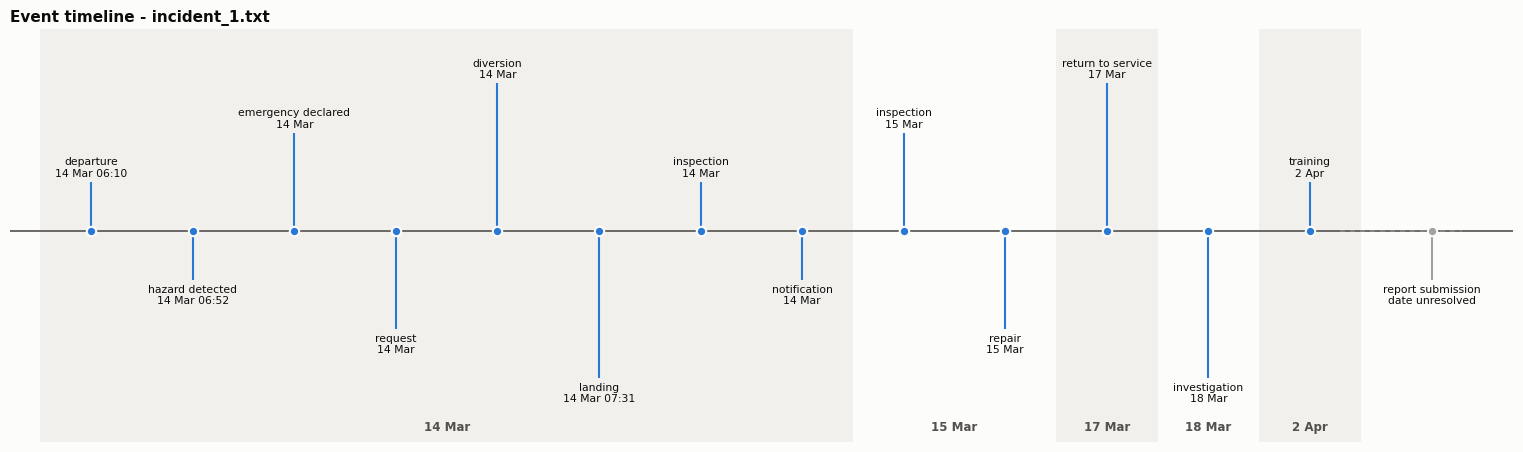

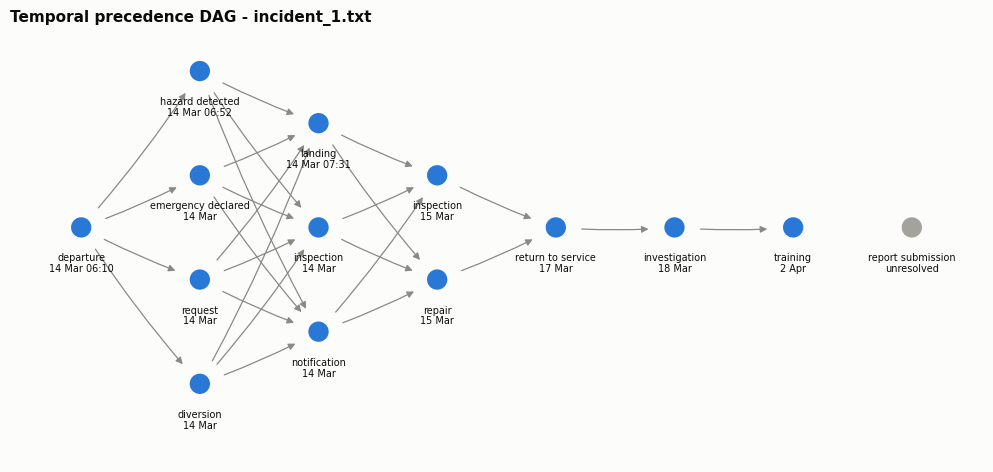

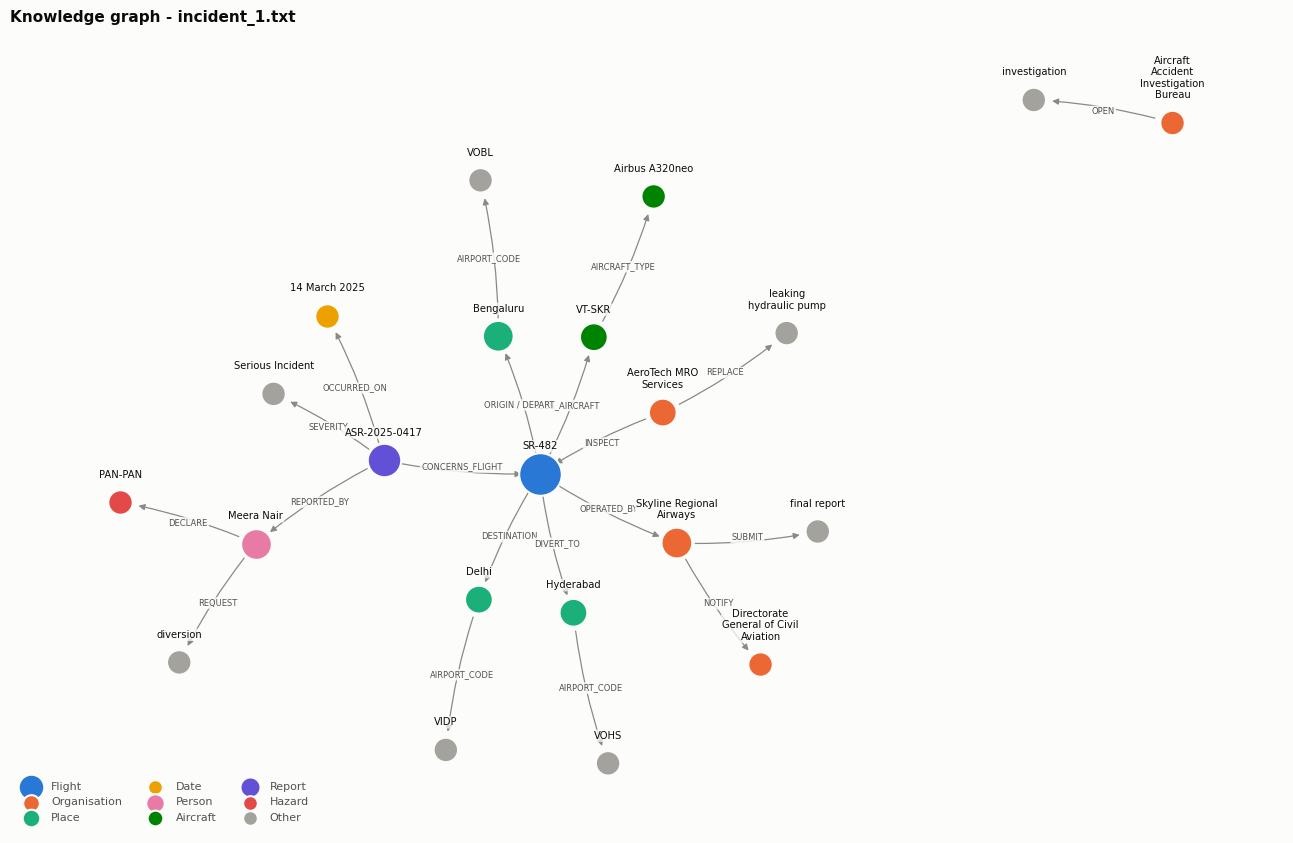

In [41]:
timeline_figure(res.timeline, "Event timeline - incident_1.txt"); plt.show()
temporal_dag_figure(res.temporal_graph, "Temporal precedence DAG - incident_1.txt"); plt.show()
kg_figure(res.knowledge_graph, "Knowledge graph - incident_1.txt"); plt.show()

### 9.6 A scanned report end-to-end (`incident_scan_2.jpg`)
This one shows why temporal ordering matters: the tow bar failed at **02:24 UTC**, *before* the scheduled **02:30** departure that is mentioned first, and the rebooking (20 Nov) is mentioned before the inspection (19 Nov).

,rank,event_type,trigger,date,time,anchoring
0,1,EQUIPMENT_FAILURE,sheared,2024-11-19,02:24,"time explicit, date inherited"
1,2,COLLISION,contacted,2024-11-19,None,inherited from discourse
2,3,ENGINE_SHUTDOWN,stopped,2024-11-19,None,inherited from discourse
3,4,CANCELLATION,cancelled,2024-11-19,None,inherited from discourse
4,5,INSPECTION,inspected,2024-11-19,None,explicit
5,6,NOTIFICATION,notified,2024-11-19,None,explicit
6,7,PLANNED_DEPARTURE,depart,2024-11-19,02:30,explicit
7,8,REPAIR,repaired,2024-11-21,None,explicit
8,9,RETURN_TO_SERVICE,released,2024-11-22,None,explicit
9,10,TRAINING,retrain,None,None,unresolved (duration: 2 weeks)


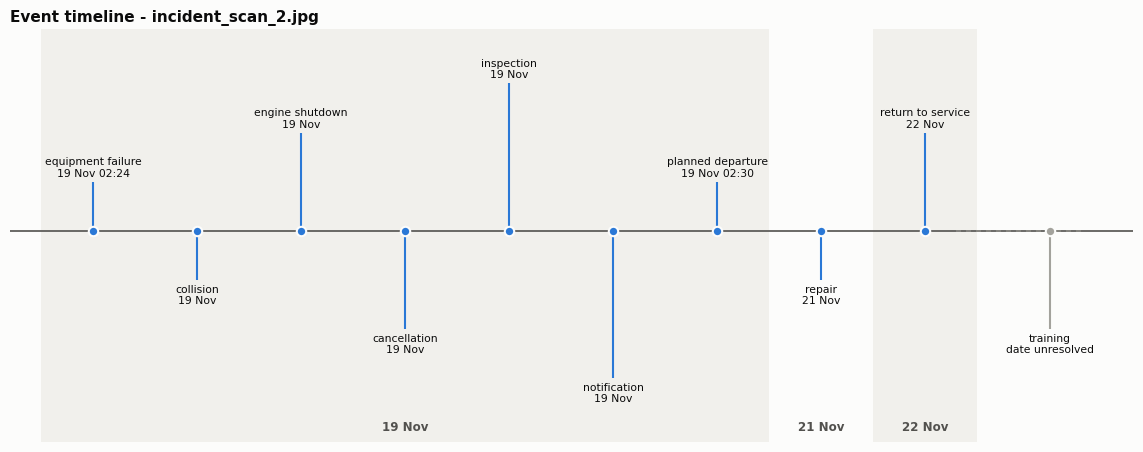

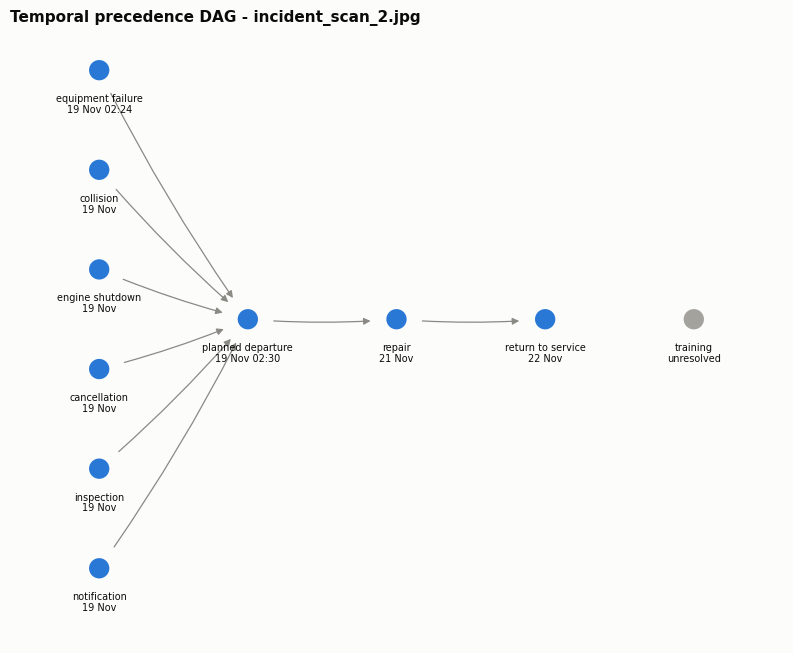

In [42]:
res2 = run_pipeline(preprocess_and_ocr(ROOT / "sample_data/incident_scan_2.jpg")["text"])
display(res2.timeline[["rank", "event_type", "trigger", "date", "time", "anchoring"]])
timeline_figure(res2.timeline, "Event timeline - incident_scan_2.jpg"); plt.show()
temporal_dag_figure(res2.temporal_graph, "Temporal precedence DAG - incident_scan_2.jpg"); plt.show()

### 9.7 Run every report and save all deliverables to `outputs/`

In [43]:
OUT = ROOT / "outputs"
IMAGE_EXT = (".png", ".jpg", ".jpeg")

def save_outputs(path, res, ocr_text=None):
    d = OUT / path.stem
    d.mkdir(parents=True, exist_ok=True)
    if ocr_text:
        (d / "ocr_text.txt").write_text(ocr_text)
    (d / "annotated.html").write_text(f"<!doctype html><meta charset='utf-8'><title>{path.name}</title>"
                                      f"<body style='font-family:Georgia;max-width:900px;margin:30px auto;line-height:2'>"
                                      f"{annotated_html(res.doc)}</body>")
    (d / "annotated_tokens.tsv").write_text(conll_annotations(res.doc))
    for name in ["pos", "entities", "relations", "events", "timeline"]:
        getattr(res, name).to_csv(d / f"{name}.csv", index=False)
    save(timeline_figure(res.timeline, f"Event timeline - {path.name}"), d / "timeline.png")
    save(temporal_dag_figure(res.temporal_graph, f"Temporal precedence DAG - {path.name}"), d / "temporal_dag.png")
    save(kg_figure(res.knowledge_graph, f"Knowledge graph - {path.name}"), d / "knowledge_graph.png")

summary = []
for path in sorted((ROOT / "sample_data").iterdir()):
    text = preprocess_and_ocr(path)["text"] if path.suffix in IMAGE_EXT else path.read_text()
    r = run_pipeline(text)
    save_outputs(path, r, text if path.suffix in IMAGE_EXT else None)
    summary.append({"report": path.name, "input": "scan (OCR)" if path.suffix in IMAGE_EXT else "text",
                    "schema entities": int(r.entities["in_schema"].sum()), "relations": len(r.relations),
                    "events": len(r.events), "unresolved dates": int(r.timeline["date"].isna().sum())})
pd.DataFrame(summary)

,report,input,schema entities,relations,events,unresolved dates
0,incident_1.txt,text,34,21,14,1
1,incident_2.txt,text,33,21,13,0
2,incident_3.txt,text,32,19,8,0
3,incident_scan_1.png,scan (OCR),30,17,11,0
4,incident_scan_2.jpg,scan (OCR),28,19,10,1


## 10. Evaluation against the gold standard
* **Entities** — multiset of (label, text), exact match. Compared with a **spaCy-only ablation** (statistical NER mapped to the schema) to measure what the domain layer adds.
* **Relations** — subject + relation exact, object exact or gold head-noun contained in the predicted phrase.
* **Events** — detection P/R/F1 over event types; date and clock-time accuracy of matched events; **pairwise ordering accuracy** over event pairs whose order the gold standard determines, compared with a **narrative-order baseline** (events in the order they are mentioned).
* Scores are reported separately for the **development** documents (used while writing the rules) and the **held-out** documents.

In [44]:
GOLD = json.loads((ROOT / "gold/gold_annotations.json").read_text())
EVAL_OUT = ROOT / "outputs/evaluation"
DOCS = [k for k in GOLD if not k.startswith("_")]
SPLIT = {d: ("dev" if d in GOLD["_schema"]["splits"]["development"] else "test") for d in DOCS}
GT_TEXT = {"incident_scan_1.png": "gold/incident_scan_1_groundtruth.txt",
           "incident_scan_2.jpg": "gold/incident_scan_2_groundtruth.txt"}


def norm(s: str) -> str:
    return re.sub(r"\s+", " ", str(s)).strip()


def load_text(name: str, use_ocr: bool = True) -> str:
    path = ROOT / "sample_data" / name
    if name.endswith((".png", ".jpg", ".jpeg")):
        if use_ocr:
            return preprocess_and_ocr(path)["text"]
        return (ROOT / GT_TEXT[name]).read_text()
    return path.read_text()


def prf(tp: int, n_pred: int, n_gold: int) -> dict:
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gold if n_gold else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {"tp": tp, "pred": n_pred, "gold": n_gold, "precision": round(p, 3),
            "recall": round(r, 3), "f1": round(f, 3)}


# ------------------------------------------------------------------ entities
def entity_counts(ents: pd.DataFrame) -> Counter:
    ents = ents[ents["label"].isin(SCHEMA_LABELS)]
    return Counter((r.label, norm(r.text)) for r in ents.itertuples())


def spacy_only_entities(text: str) -> pd.DataFrame:
    """Ablation: the statistical model alone, mapped to the schema as fairly as possible."""
    doc = get_nlp()(normalise_text(text))
    rows = []
    for e in doc.ents:
        lab = {"LOC": "GPE"}.get(e.label_, e.label_)
        if lab in ("DATE", "TIME") and _DURATION_RE.search(e.text) and not _CALENDAR_RE.search(e.text):
            continue
        rows.append({"text": canon(e.text), "label": lab})
    return pd.DataFrame(rows, columns=["text", "label"])


def score_entities(pred: Counter, gold: Counter) -> tuple[dict, list, list]:
    tp = sum((pred & gold).values())
    fp = list((pred - gold).elements())
    fn = list((gold - pred).elements())
    return prf(tp, sum(pred.values()), sum(gold.values())), fp, fn


# ------------------------------------------------------------------ relations
def rel_match(pred: tuple, gold: tuple) -> bool:
    ps, pr, po = (norm(x).lower() for x in pred)
    gs, gr, go = (norm(x).lower() for x in gold)
    return ps == gs and pr == gr and (po == go or go in po.split() or go in po)


def score_relations(pred: list[tuple], gold: list[tuple]) -> tuple[dict, list, list]:
    used, tp, fn = set(), 0, []
    for g in gold:
        hit = next((i for i, p in enumerate(pred) if i not in used and rel_match(p, g)), None)
        if hit is None:
            fn.append(g)
        else:
            used.add(hit)
            tp += 1
    fp = [p for i, p in enumerate(pred) if i not in used]
    return prf(tp, len(pred), len(gold)), fp, fn


# ------------------------------------------------------------------ events
def match_events(pred: pd.DataFrame, gold: list) -> list[tuple[int, int]]:
    """Pair gold and predicted events of the same type, both taken in text order."""
    pairs, used = [], set()
    for gi, (gtype, _, _) in enumerate(gold):
        for pi, r in enumerate(pred.itertuples()):
            if pi not in used and r.event_type == gtype:
                pairs.append((gi, pi))
                used.add(pi)
                break
    return pairs


def comparable(a, b) -> int | None:
    """Gold order of two events: -1 (a first), 1 (b first) or None (not determinable)."""
    (_, da, ta), (_, db, tb) = a, b
    if not da or not db:
        return None
    if da != db:
        return -1 if da < db else 1
    if ta and tb and ta != tb:
        return -1 if ta < tb else 1
    return None


def score_events(pred_events: pd.DataFrame, timeline: pd.DataFrame, gold: list) -> dict:
    pc = Counter(pred_events["event_type"])
    gc = Counter(g[0] for g in gold)
    det = prf(sum((pc & gc).values()), sum(pc.values()), sum(gc.values()))
    pairs = match_events(pred_events, gold)
    def _d(v):
        return v if isinstance(v, str) else None
    date_ok = sum(1 for gi, pi in pairs if _d(pred_events.iloc[pi]["date"]) == gold[gi][1])
    timed = [(gi, pi) for gi, pi in pairs if gold[gi][2]]
    time_ok = sum(1 for gi, pi in timed if pred_events.iloc[pi]["time"] == gold[gi][2])
    rank_of = {int(r["order"]): int(r["rank"]) for _, r in timeline.iterrows()}
    order_of = {gi: int(pred_events.iloc[pi]["order"]) for gi, pi in pairs}
    n_pairs = sys_ok = base_ok = 0
    for a, b in combinations(order_of, 2):
        rel = comparable(gold[a], gold[b])
        if rel is None:
            continue
        n_pairs += 1
        sys_ok += (rank_of[order_of[a]] < rank_of[order_of[b]]) == (rel < 0)
        base_ok += (order_of[a] < order_of[b]) == (rel < 0)
    return {"detection": det, "matched": len(pairs),
            "date_correct": date_ok, "time_checked": len(timed), "time_correct": time_ok,
            "ordering_pairs": n_pairs, "ordering_correct": sys_ok, "baseline_correct": base_ok}


# ------------------------------------------------------------------ main
def main() -> dict:
    EVAL_OUT.mkdir(parents=True, exist_ok=True)
    metrics = {"ocr": {}, "per_document": {}}
    tot = {k: Counter() for k in ["hybrid", "spacy", "hybrid_gt_text"]}
    gold_tot = Counter()
    split_tot = {"dev": [Counter(), Counter()], "test": [Counter(), Counter()]}
    per_label = []
    err_rows = []
    rel_all = {"field": [[], []], "narrative": [[], []]}
    rel_split = {"dev": [[], []], "test": [[], []]}
    ev_rows = []

    for name in DOCS:
        g = GOLD[name]
        text = load_text(name)
        res = run_pipeline(text)
        gold_e = Counter((lab, norm(t)) for lab, t in g["entities"])
        pred_e = entity_counts(res.entities)
        sp_e = entity_counts(spacy_only_entities(text))
        tot["hybrid"] += pred_e
        tot["spacy"] += sp_e
        gold_tot += gold_e
        split_tot[SPLIT[name]][0] += pred_e
        split_tot[SPLIT[name]][1] += gold_e
        if name in GT_TEXT:
            gt_res = run_pipeline(load_text(name, use_ocr=False))
            tot["hybrid_gt_text"] += entity_counts(gt_res.entities)
            o = preprocess_and_ocr(ROOT / "sample_data" / name)
            raw = preprocess_and_ocr(ROOT / "sample_data" / name, raw=True)
            gt = (ROOT / GT_TEXT[name]).read_text()
            metrics["ocr"][name] = {"char_accuracy_preprocessed": round(char_accuracy(o["text"], gt), 4),
                                   "char_accuracy_raw": round(char_accuracy(raw["text"], gt), 4),
                                   "detected_skew_deg": round(o["angle"], 2)}
        else:
            tot["hybrid_gt_text"] += pred_e
        s, fp, fn = score_entities(pred_e, gold_e)
        for lab, t in fp:
            err_rows.append({"document": name, "type": "FP", "label": lab, "text": t})
        for lab, t in fn:
            err_rows.append({"document": name, "type": "FN", "label": lab, "text": t})

        pred_r = [(r.subject, r.relation, r.object) for r in res.relations.itertuples()]
        pred_field = [(r.subject, r.relation, r.object) for r in res.relations.itertuples() if r.source == "field"]
        pred_narr = [(r.subject, r.relation, r.object) for r in res.relations.itertuples() if r.source == "narrative"]
        rel_doc = {}
        for kind, pr in (("field", pred_field), ("narrative", pred_narr)):
            gr = [tuple(x) for x in g["relations"][kind]]
            sc, rfp, rfn = score_relations(pr, gr)
            rel_doc[kind] = sc
            rel_all[kind][0].append((sc["tp"], sc["pred"], sc["gold"]))
            for x in rfp:
                err_rows.append({"document": name, "type": "FP", "label": f"REL/{kind}", "text": " | ".join(x)})
            for x in rfn:
                err_rows.append({"document": name, "type": "FN", "label": f"REL/{kind}", "text": " | ".join(x)})
        allg = [tuple(x) for x in g["relations"]["field"] + g["relations"]["narrative"]]
        sc_all, _, _ = score_relations(pred_r, allg)
        rel_split[SPLIT[name]][0].append((sc_all["tp"], sc_all["pred"], sc_all["gold"]))

        ev = score_events(res.events, res.timeline, [tuple(x) for x in g["events"]])
        ev_rows.append({"document": name, "split": SPLIT[name], **{k: v for k, v in ev.items() if k != "detection"},
                        **{f"det_{k}": v for k, v in ev["detection"].items()}})
        pe = Counter(res.events["event_type"])
        ge = Counter(x[0] for x in g["events"])
        for t in (pe - ge).elements():
            err_rows.append({"document": name, "type": "FP", "label": "EVENT", "text": t})
        for t in (ge - pe).elements():
            err_rows.append({"document": name, "type": "FN", "label": "EVENT", "text": t})

        metrics["per_document"][name] = {"split": SPLIT[name], "entities": s, "relations": rel_doc,
                                         "events": ev}

    # aggregate -----------------------------------------------------------------
    def agg(c_pred, c_gold):
        return prf(sum((c_pred & c_gold).values()), sum(c_pred.values()), sum(c_gold.values()))

    metrics["ner"] = {
        "hybrid_all": agg(tot["hybrid"], gold_tot),
        "spacy_only_all": agg(tot["spacy"], gold_tot),
        "hybrid_dev": agg(*split_tot["dev"]),
        "hybrid_test": agg(*split_tot["test"]),
        "hybrid_with_ground_truth_text_for_scans": agg(tot["hybrid_gt_text"], gold_tot),
    }
    for lab in SCHEMA_LABELS:
        pc = Counter({k: v for k, v in tot["hybrid"].items() if k[0] == lab})
        sc = Counter({k: v for k, v in tot["spacy"].items() if k[0] == lab})
        gc = Counter({k: v for k, v in gold_tot.items() if k[0] == lab})
        h = agg(pc, gc)
        b = agg(sc, gc)
        per_label.append({"label": lab, "gold": h["gold"], "hybrid_P": h["precision"], "hybrid_R": h["recall"],
                          "hybrid_F1": h["f1"], "spacy_only_F1": b["f1"]})

    def sum_prf(lst):
        tp, pr, go = (sum(x[i] for x in lst) for i in range(3))
        return prf(tp, pr, go)

    metrics["relations"] = {"field": sum_prf(rel_all["field"][0]), "narrative": sum_prf(rel_all["narrative"][0]),
                            "dev": sum_prf(rel_split["dev"][0]), "test": sum_prf(rel_split["test"][0])}
    evdf = pd.DataFrame(ev_rows)
    metrics["events"] = {
        "detection": prf(int(evdf.det_tp.sum()), int(evdf.det_pred.sum()), int(evdf.det_gold.sum())),
        "date_accuracy": round(evdf.date_correct.sum() / evdf.matched.sum(), 3),
        "date_correct": int(evdf.date_correct.sum()), "matched": int(evdf.matched.sum()),
        "time_accuracy": round(evdf.time_correct.sum() / max(1, evdf.time_checked.sum()), 3),
        "time_correct": int(evdf.time_correct.sum()), "time_checked": int(evdf.time_checked.sum()),
        "ordering_pairs": int(evdf.ordering_pairs.sum()),
        "ordering_accuracy": round(evdf.ordering_correct.sum() / max(1, evdf.ordering_pairs.sum()), 3),
        "narrative_baseline_accuracy": round(evdf.baseline_correct.sum() / max(1, evdf.ordering_pairs.sum()), 3),
    }
    for sp in ("dev", "test"):
        d = evdf[evdf.split == sp]
        metrics["events"][f"detection_{sp}"] = prf(int(d.det_tp.sum()), int(d.det_pred.sum()), int(d.det_gold.sum()))

    pd.DataFrame(per_label).to_csv(EVAL_OUT / "ner_per_label.csv", index=False)
    pd.DataFrame(err_rows).to_csv(EVAL_OUT / "errors.csv", index=False)
    evdf.to_csv(EVAL_OUT / "events_per_document.csv", index=False)
    (EVAL_OUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
    return metrics

In [45]:
metrics = main()
ner = metrics["ner"]
display(pd.DataFrame({k: ner[k] for k in ["hybrid_all", "spacy_only_all", "hybrid_dev", "hybrid_test",
                                          "hybrid_with_ground_truth_text_for_scans"]}).T[["tp", "pred", "gold", "precision", "recall", "f1"]])
pd.read_csv(EVAL_OUT / "ner_per_label.csv")

,tp,pred,gold,precision,recall,f1
hybrid_all,155.0,157.0,157.0,0.987,0.987,0.987
spacy_only_all,78.0,116.0,157.0,0.672,0.497,0.571
hybrid_dev,64.0,64.0,64.0,1.000,1.000,1.000
hybrid_test,91.0,93.0,93.0,0.978,0.978,0.978
hybrid_with_ground_truth_text_for_scans,156.0,157.0,157.0,0.994,0.994,0.994


,label,gold,hybrid_P,hybrid_R,hybrid_F1,spacy_only_F1
0,PERSON,9,1.000,1.000,1.000,0.900
1,ORG,26,0.923,0.923,0.923,0.593
2,GPE,23,1.000,1.000,1.000,0.667
3,DATE,33,1.000,1.000,1.000,0.909
4,TIME,14,1.000,1.000,1.000,0.333
5,REPORT_ID,5,1.000,1.000,1.000,0.000
6,FLIGHT_NO,10,1.000,1.000,1.000,0.000
7,REGISTRATION,5,1.000,1.000,1.000,0.000
8,AIRCRAFT_TYPE,5,1.000,1.000,1.000,0.000
9,AIRPORT_CODE,12,1.000,1.000,1.000,0.000


In [46]:
rel = pd.DataFrame(metrics["relations"]).T[["tp", "pred", "gold", "precision", "recall", "f1"]]
display(rel)
ev = metrics["events"]
display(pd.DataFrame({"detection - all": ev["detection"], "detection - dev": ev["detection_dev"],
                      "detection - held-out": ev["detection_test"]}).T[["tp", "pred", "gold", "precision", "recall", "f1"]])
pd.DataFrame([
    {"measure": "date accuracy (matched events)", "value": f'{ev["date_correct"]}/{ev["matched"]} = {ev["date_accuracy"]}'},
    {"measure": "clock-time accuracy (gold states a time)", "value": f'{ev["time_correct"]}/{ev["time_checked"]} = {ev["time_accuracy"]}'},
    {"measure": "pairwise ordering accuracy - pipeline", "value": f'{ev["ordering_accuracy"]} over {ev["ordering_pairs"]} pairs'},
    {"measure": "pairwise ordering accuracy - narrative-order baseline", "value": str(ev["narrative_baseline_accuracy"])},
])

,tp,pred,gold,precision,recall,f1
field,56.0,56.0,57.0,1.000,0.982,0.991
narrative,36.0,41.0,39.0,0.878,0.923,0.900
dev,38.0,38.0,38.0,1.000,1.000,1.000
test,54.0,59.0,58.0,0.915,0.931,0.923


,tp,pred,gold,precision,recall,f1
detection - all,56.0,56.0,64.0,1.0,0.875,0.933
detection - dev,25.0,25.0,26.0,1.0,0.962,0.980
detection - held-out,31.0,31.0,38.0,1.0,0.816,0.899


,measure,value
0,date accuracy (matched events),56/56 = 1.0
1,clock-time accuracy (gold states a time),12/12 = 1.0
2,pairwise ordering accuracy - pipeline,1.0 over 178 pairs
3,pairwise ordering accuracy - narrative-order baseline,0.983


### Error analysis — every false positive (FP) and false negative (FN)

In [47]:
pd.read_csv(EVAL_OUT / "errors.csv")

,document,type,label,text
0,incident_2.txt,FP,ORG,First Officer
1,incident_2.txt,FP,REL/narrative,Coastal Wings Engineering | INSPECT_WITH | borescope
2,incident_2.txt,FP,REL/narrative,Airports Authority of India | REVIEW_AT | Chennai
3,incident_2.txt,FN,EVENT,REBOOKING
4,incident_scan_1.png,FN,EVENT,MEDICAL_RESPONSE
5,incident_scan_2.jpg,FP,ORG,Norther Star Airlines
6,incident_scan_2.jpg,FN,ORG,Northern Star Airlines
7,incident_scan_2.jpg,FP,REL/narrative,Norther Star Airlines | CANCEL | NS-130
8,incident_scan_2.jpg,FP,REL/narrative,Norther Star Airlines | REBOOKE | passengers
9,incident_scan_2.jpg,FN,REL/narrative,NS-130 | DEPART | Delhi


## 11. Findings
* The **domain layer carries the NER**: spaCy alone scores far lower because it has never seen flight numbers, registrations, ICAO codes or UTC times and often mislabels airport cities as ORG/PERSON; label propagation repairs the latter.
* **OCR preprocessing** is what makes the scanned reports usable at all (compare the raw vs. preprocessed character accuracy above); residual OCR errors (e.g. `all → al]`) still propagate into NER and relations.
* **Relation and event extraction are precise but recall-limited**: they only fire on verbs and constructions in the rules/lexicon. On the report written after the rules were frozen (`incident_3.txt`) event recall drops sharply (*took off*, *began an investigation*, *received treatment*, *publish* are not triggers) — the clearest sign of over-fitting to the development documents.
* **Temporal ordering** is reliable once dates are anchored; its gain over plain narrative order is visible on `incident_scan_2.jpg`, where events are mentioned out of chronological order.
* Limitations: a small, self-authored corpus (the held-out reports share the same template, so held-out scores are optimistic); a single annotator; rule-based coreference only for aircraft/flight mentions.